In [3]:
import pandas as pd
import numpy as np
train_df=pd.read_csv('train.csv')

In [4]:
train_df.describe()

,sk_id_curr,TARGET,cnt_children,amt_income_total,amt_credit,amt_annuity,amt_goods_price,region_population_relative,days_birth,days_employed,...,refused_count,approval_rate,refusal_rate,max_approved_credit,avg_approved_credit,min_refused_credit,max_approved_annuity,avg_approved_annuity,latest_previous_application,avg_previous_credit
count,307511.000000,307511.000000,307511.000000,3.075110e+05,3.075110e+05,307499.000000,3.072330e+05,307511.000000,307511.000000,307511.000000,...,291057.000000,291057.000000,291057.000000,2.900650e+05,2.900650e+05,1.002940e+05,290063.000000,290063.000000,291057.000000,2.910570e+05
mean,278180.518577,0.080729,0.417052,1.687979e+05,5.990260e+05,27108.573909,5.383962e+05,0.020868,-16036.995067,63815.045904,...,0.843099,0.748855,0.110902,3.434410e+05,1.832248e+05,2.402623e+05,21635.638729,13925.746444,-480.816819,1.700700e+05
std,102790.175348,0.272419,0.722121,2.371231e+05,4.024908e+05,14493.737315,3.694465e+05,0.013831,4363.988632,141275.766519,...,1.813868,0.262332,0.184348,3.800036e+05,1.771062e+05,3.650921e+05,17708.475782,9846.949637,540.186089,1.657372e+05
min,100002.000000,0.000000,0.000000,2.565000e+04,4.500000e+04,1615.500000,4.050000e+04,0.000290,-25229.000000,-17912.000000,...,0.000000,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,-2922.000000,0.000000e+00
25%,189145.500000,0.000000,0.000000,1.125000e+05,2.700000e+05,16524.000000,2.385000e+05,0.010006,-19682.000000,-2760.000000,...,0.000000,0.500000,0.000000,9.324000e+04,7.101450e+04,4.022212e+04,9556.740000,7487.538635,-595.000000,6.684943e+04
50%,278202.000000,0.000000,0.000000,1.471500e+05,5.135310e+05,24903.000000,4.500000e+05,0.018850,-15750.000000,-1213.000000,...,0.000000,0.800000,0.000000,1.822185e+05,1.255650e+05,1.074510e+05,16143.525000,11373.480469,-299.000000,1.174500e+05
75%,367142.500000,0.000000,1.000000,2.025000e+05,8.086500e+05,34596.000000,6.795000e+05,0.028663,-12413.000000,-289.000000,...,1.000000,1.000000,0.200000,4.500000e+05,2.348932e+05,2.573888e+05,28180.890000,17435.632411,-147.000000,2.160720e+05
max,456255.000000,1.000000,19.000000,1.170000e+08,4.050000e+06,258025.500000,4.050000e+06,0.072508,-7489.000000,365243.000000,...,68.000000,1.000000,1.000000,4.509688e+06,4.050000e+06,4.085550e+06,393868.660000,300425.437500,-1.000000,4.050000e+06


## Anomaly: `days_employed`

**Key observation:** The column represents days employed as a negative
offset from the application date (e.g. `-2760` means employment started
2760 days ago), so values should be zero or negative. However, the
maximum value is `365243` (~1000 years), which is not a plausible
employment duration.

**Cause:** `365243` is a known placeholder code used by Home Credit to
flag pensioners and unemployed applicants, rather than a genuine day
count.

**Note:** A binary flag will be created to preserve this signal before
the placeholder is replaced and imputed, so the "unemployed/pensioner"
information isn't lost during correction.

## Anomaly: `amt_income_total`

**Key observation:** `std` (237,123) exceeds `mean` (168,798), and the
maximum value (117,000,000) is far beyond any plausible individual
income — a strong sign of a heavily right-skewed distribution driven by
one or a few extreme outliers, likely data entry errors.

**Note:** This will be clipped at the 99th percentile and log-transformed,
with the threshold computed on `train_df` only to avoid data leakage.

## Anomaly: `amt_req_credit_bureau_qrt`

**Key observation:** The 75th percentile is `0`, meaning most applicants
had zero bureau inquiries in a given quarter, yet the maximum value is
`261` — roughly 3 inquiries per day, which is not realistic and
disproportionately skews the mean.

**Note:** This will be clipped at a high percentile (99.9th) to cap the
extreme value without discarding rows, computed on `train_df` only.

## Anomaly: `own_car_age`

**Key observation:** The maximum value is `91` years, which is not a
realistic age for a vehicle in this context and likely reflects a data
entry error or placeholder code.

**Note:** This will be clipped at the 99th percentile, computed on
`train_df` only.

## Anomaly: `payment_ratio` (engineered feature)

**Key observation:** Most values cluster tightly around `1.0` (payment
matches the scheduled installment amount), but the maximum reaches
`5.485` — a customer paying 5.5x the scheduled amount is implausible at
that scale and likely reflects extreme values in the underlying
`AMT_INSTALMENT` / `AMT_PAYMENT` fields.

**Note:** This will be clipped at the 99th percentile, computed on
`train_df` only.

---------------------------------------------------------------------------------------------

### Fixing the `days_employed` Anomaly

In [5]:
print((train_df['days_employed'] == 365243).sum())

55374


In [6]:
# Flag the placeholder value before replacing it with NaN
train_df['days_employed_anomaly'] = (train_df['days_employed'] == 365243).astype(int)
train_df['days_employed'] = train_df['days_employed'].replace(365243, np.nan)

/var/folders/yt/vzj07vbd1gv2mjpzwt562v_m0000gn/T/ipykernel_47781/914713084.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  train_df['days_employed_anomaly'] = (train_df['days_employed'] == 365243).astype(int)


In [7]:
print(train_df['days_employed'].describe())
print(train_df['days_employed_anomaly'].value_counts())

count    252137.000000
mean      -2384.169325
std        2338.360162
min      -17912.000000
25%       -3175.000000
50%       -1648.000000
75%        -767.000000
max           0.000000
Name: days_employed, dtype: float64
days_employed_anomaly
0    252137
1     55374
Name: count, dtype: int64


---------------------------------------------------------------------------------------------

### Fixing the `amt_income_total` Anomaly

In [8]:
# Clip values above the 99th percentile to limit the influence of extreme outliers
income_upper = train_df['amt_income_total'].quantile(0.99)
print('Clip threshold:', income_upper)

train_df['amt_income_total'] = train_df['amt_income_total'].clip(upper=income_upper)

Clip threshold: 472500.0


In [9]:
# Log transform to correct the remaining right skew
train_df['amt_income_total_log'] = np.log1p(train_df['amt_income_total'])

/var/folders/yt/vzj07vbd1gv2mjpzwt562v_m0000gn/T/ipykernel_47781/870514299.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  train_df['amt_income_total_log'] = np.log1p(train_df['amt_income_total'])


In [10]:
print(train_df['amt_income_total'].describe())
print('Skewness (clip-dən sonra):', train_df['amt_income_total'].skew())
print('Skewness (log-dan sonra):', train_df['amt_income_total_log'].skew())

count    307511.000000
mean     166025.922341
std       83063.469251
min       25650.000000
25%      112500.000000
50%      147150.000000
75%      202500.000000
max      472500.000000
Name: amt_income_total, dtype: float64
Skewness (clip-dən sonra): 1.3501802773295801
Skewness (log-dan sonra): -0.017229138141703543


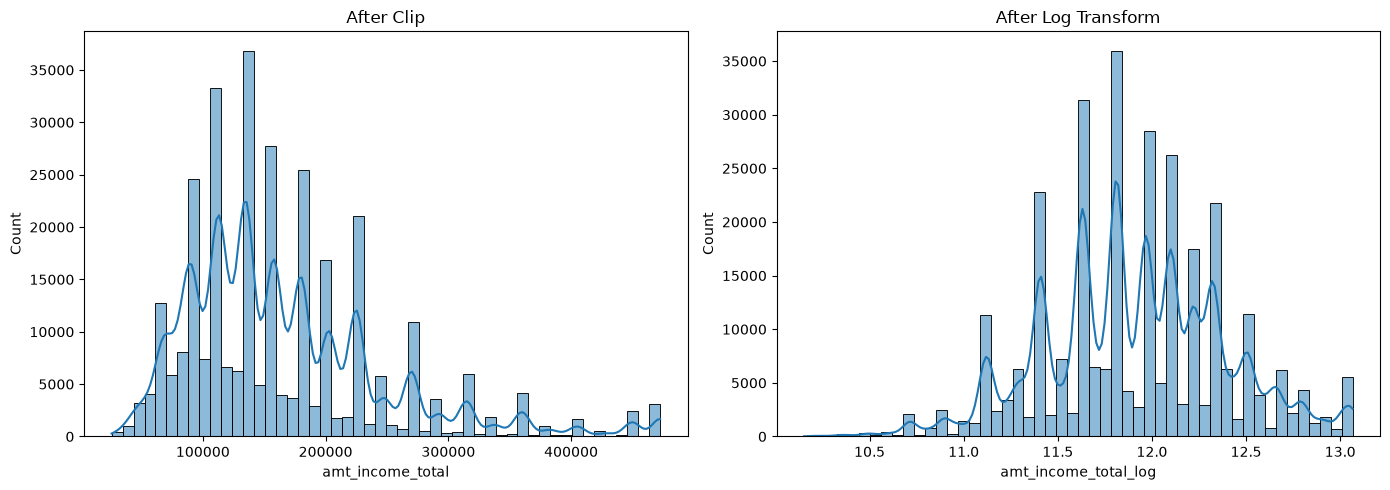

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(train_df['amt_income_total'], kde=True, bins=50, ax=axes[0])
axes[0].set_title('After Clip')

sns.histplot(train_df['amt_income_total_log'], kde=True, bins=50, ax=axes[1])
axes[1].set_title('After Log Transform')

plt.tight_layout()
plt.show()

---------------------------------------------------------------------------------------------

### Fixing the `amt_req_credit_bureau_qrt` Anomaly

In [12]:
print(train_df['amt_req_credit_bureau_qrt'].value_counts().sort_index(ascending=False).head(15))

amt_req_credit_bureau_qrt
261.0         1
19.0          1
8.0           7
7.0           7
6.0          28
5.0          64
4.0         476
3.0        1717
2.0       14412
1.0       33862
0.0      215417
Name: count, dtype: int64


In [13]:
qrt_upper = train_df['amt_req_credit_bureau_qrt'].quantile(0.999)
print('Clip threshold:', qrt_upper)

train_df['amt_req_credit_bureau_qrt'] = train_df['amt_req_credit_bureau_qrt'].clip(upper=qrt_upper)

Clip threshold: 4.0


 Result: `amt_req_credit_bureau_qrt` Capped at 4.0
 Clipping at the 99.9th percentile reduced the maximum from 261 to 4,
removing the single extreme anomaly while preserving the natural
distribution of the remaining values (which are almost entirely 0–4).

In [14]:
print(train_df['amt_req_credit_bureau_qrt'].describe())
print('Max dəyər (clip-dən sonra):', train_df['amt_req_credit_bureau_qrt'].max())

count    265992.000000
mean          0.263816
std           0.606350
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max           4.000000
Name: amt_req_credit_bureau_qrt, dtype: float64
Max dəyər (clip-dən sonra): 4.0


---------------------------------------------------------------------------------------------

### Fixing the `payment_ratio` Anomaly

In [15]:
ratio_upper = train_df['payment_ratio'].quantile(0.99)
print('Clip threshold:', ratio_upper)

Clip threshold: 1.5809142930000002


Result: `payment_ratio` Capped at 1.57.
Clipping at the 99th percentile reduced the maximum from 5.49 to 1.57,
removing the extreme outliers while preserving the natural distribution
of values clustered around 1.0.

In [16]:
train_df['payment_ratio'] = train_df['payment_ratio'].clip(upper=ratio_upper)

---------------------------------------------------------------------------------------------

In [17]:
class_counts = train_df['TARGET'].value_counts().rename('count').to_frame()
class_counts['percentage'] = (class_counts['count'] / len(train_df) * 100).round(2)
print(class_counts)

         count  percentage
TARGET                    
0       282686       91.93
1        24825        8.07


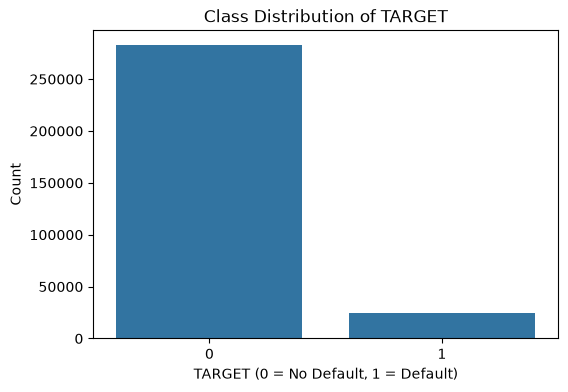

In [18]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))
sns.countplot(x='TARGET', data=train_df)

plt.title('Class Distribution of TARGET')
plt.xlabel('TARGET (0 = No Default, 1 = Default)')
plt.ylabel('Count')

plt.show()

In [19]:
numeric_cols = train_df.select_dtypes(include='number').columns.tolist()
categorical_cols = train_df.select_dtypes(include=['object', 'category']).columns.tolist()

print(f"Numeric columns ({len(numeric_cols)}):")
print(numeric_cols)

print(f"\nCategorical columns ({len(categorical_cols)}):")
print(categorical_cols)

Numeric columns (162):
['sk_id_curr', 'TARGET', 'cnt_children', 'amt_income_total', 'amt_credit', 'amt_annuity', 'amt_goods_price', 'region_population_relative', 'days_birth', 'days_employed', 'days_registration', 'days_id_publish', 'own_car_age', 'flag_mobil', 'flag_emp_phone', 'flag_work_phone', 'flag_cont_mobile', 'flag_phone', 'flag_email', 'cnt_fam_members', 'region_rating_client', 'region_rating_client_w_city', 'hour_appr_process_start', 'reg_region_not_live_region', 'reg_region_not_work_region', 'live_region_not_work_region', 'reg_city_not_live_city', 'reg_city_not_work_city', 'live_city_not_work_city', 'ext_source_1', 'ext_source_2', 'ext_source_3', 'apartments_avg', 'basementarea_avg', 'years_beginexpluatation_avg', 'years_build_avg', 'commonarea_avg', 'elevators_avg', 'entrances_avg', 'floorsmax_avg', 'floorsmin_avg', 'landarea_avg', 'livingapartments_avg', 'livingarea_avg', 'nonlivingapartments_avg', 'nonlivingarea_avg', 'apartments_mode', 'basementarea_mode', 'years_beginex

/var/folders/yt/vzj07vbd1gv2mjpzwt562v_m0000gn/T/ipykernel_47781/841625027.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = train_df.select_dtypes(include=['object', 'category']).columns.tolist()


In [20]:
train_df.shape

(307511, 178)

In [21]:
import pandas as pd
pd.set_option('display.max_rows', None)

from IPython.display import display

missing = train_df.isnull().sum()
missing_pct = (missing / len(train_df)) * 100

missing_df = pd.DataFrame({
    'column': missing.index,
    'missing_count': missing.values,
    'missing_pct': missing_pct.values.round(2)
})

missing_df = missing_df.sort_values('missing_pct', ascending=False).reset_index(drop=True)

display(missing_df)

,column,missing_count,missing_pct
0,avg_atm_drawings,246371,80.12
1,max_dpd_def,220606,71.74
2,avg_min_regularity,220606,71.74
3,dpd_frequency,220606,71.74
4,dpd_def_month_count,220606,71.74
5,dpd_month_count,220606,71.74
6,max_dpd,220606,71.74
7,avg_total_receivable,220606,71.74
8,avg_payment,220606,71.74
9,total_drawings,220606,71.74


In [22]:
credit_card_cols = [
    'card_count',  'total_credit_limit',
    'max_credit_limit', 'avg_atm_drawings', 'avg_drawings',
    'total_drawings', 'avg_min_regularity', 'avg_payment',
    'avg_total_receivable', 'max_dpd', 'max_dpd_def',
    'dpd_month_count', 'dpd_def_month_count',
    'dpd_frequency', 'dpd_def_frequency'
]

train_df[credit_card_cols] = train_df[credit_card_cols].fillna(0)

In [23]:
bureau_cols = [
    'bureau_credit_count', 'active_credit_count', 
    'total_credit_sum', 'total_debt', 'max_credit_sum', 'avg_credit_sum',
    'max_credit_day_overdue', 'total_credit_day_overdue',
    'total_observation_months', 'total_overdue_months',
    'overdue_frequency'
]
train_df[bureau_cols] = train_df[bureau_cols].fillna(0)

In [24]:
previous_app_cols = [
    'previous_application_count', 'approved_count', 'refused_count',
    'approval_rate', 'refusal_rate', 'max_approved_credit',
    'avg_approved_credit', 'min_refused_credit', 'max_approved_annuity',
    'avg_approved_annuity', 'latest_previous_application',
    'avg_previous_credit'
]

train_df[previous_app_cols] = train_df[previous_app_cols].fillna(0)

In [25]:
amt_req_bureau_time=[
    'amt_req_credit_bureau_hour','amt_req_credit_bureau_day',
    'amt_req_credit_bureau_week','amt_req_credit_bureau_mon',
    'amt_req_credit_bureau_qrt','amt_req_credit_bureau_year'
]
train_df[amt_req_bureau_time]=train_df[amt_req_bureau_time].fillna(0)

In [26]:
installment_cols = [
    'installment_credit_count', 'total_installment_count',
    'total_installment_amount', 'total_payment_amount', 'payment_ratio',
    'total_late_days', 'max_late_days', 'avg_late_days',
    'late_installment_count', 'late_payment_frequency',
    'underpaid_installment_count', 'fully_paid_installment_count',
    'total_payment_gap'
]

train_df[installment_cols] = train_df[installment_cols].fillna(0)

In [27]:
obs_def_cnt_sosial_circle=[
    'obs_60_cnt_social_circle','obs_30_cnt_social_circle',
    'def_60_cnt_social_circle','def_30_cnt_social_circle'
]
train_df[obs_def_cnt_sosial_circle]=train_df[obs_def_cnt_sosial_circle].fillna(0)

In [28]:
import pandas as pd
pd.set_option('display.max_rows', None)

from IPython.display import display

missing = train_df.isnull().sum()
missing_pct = (missing / len(train_df)) * 100

missing_df = pd.DataFrame({
    'column': missing.index,
    'missing_count': missing.values,
    'missing_pct': missing_pct.values.round(2)
})

missing_df = missing_df.sort_values('missing_pct', ascending=False).reset_index(drop=True)

display(missing_df)

,column,missing_count,missing_pct
0,total_months_balance,220606,71.74
1,max_status,215280,70.01
2,commonarea_avg,214865,69.87
3,commonarea_medi,214865,69.87
4,commonarea_mode,214865,69.87
5,nonlivingapartments_medi,213514,69.43
6,nonlivingapartments_avg,213514,69.43
7,nonlivingapartments_mode,213514,69.43
8,fondkapremont_mode,210295,68.39
9,livingapartments_mode,210199,68.35


In [29]:
numeric_cols = train_df.select_dtypes(include='number').columns.tolist()
categorical_cols = train_df.select_dtypes(include=['object', 'category']).columns.tolist()

print(f"Numeric columns ({len(numeric_cols)}):")
print(numeric_cols)

print(f"\nCategorical columns ({len(categorical_cols)}):")
print(categorical_cols)

Numeric columns (162):
['sk_id_curr', 'TARGET', 'cnt_children', 'amt_income_total', 'amt_credit', 'amt_annuity', 'amt_goods_price', 'region_population_relative', 'days_birth', 'days_employed', 'days_registration', 'days_id_publish', 'own_car_age', 'flag_mobil', 'flag_emp_phone', 'flag_work_phone', 'flag_cont_mobile', 'flag_phone', 'flag_email', 'cnt_fam_members', 'region_rating_client', 'region_rating_client_w_city', 'hour_appr_process_start', 'reg_region_not_live_region', 'reg_region_not_work_region', 'live_region_not_work_region', 'reg_city_not_live_city', 'reg_city_not_work_city', 'live_city_not_work_city', 'ext_source_1', 'ext_source_2', 'ext_source_3', 'apartments_avg', 'basementarea_avg', 'years_beginexpluatation_avg', 'years_build_avg', 'commonarea_avg', 'elevators_avg', 'entrances_avg', 'floorsmax_avg', 'floorsmin_avg', 'landarea_avg', 'livingapartments_avg', 'livingarea_avg', 'nonlivingapartments_avg', 'nonlivingarea_avg', 'apartments_mode', 'basementarea_mode', 'years_beginex

/var/folders/yt/vzj07vbd1gv2mjpzwt562v_m0000gn/T/ipykernel_47781/841625027.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = train_df.select_dtypes(include=['object', 'category']).columns.tolist()


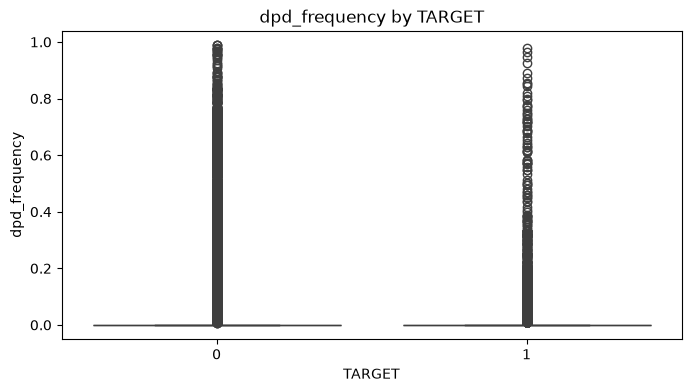

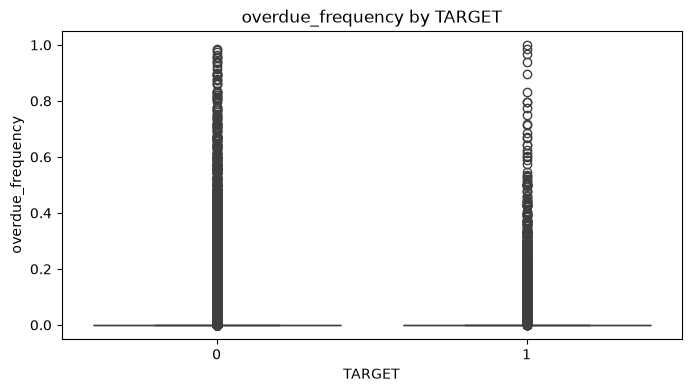

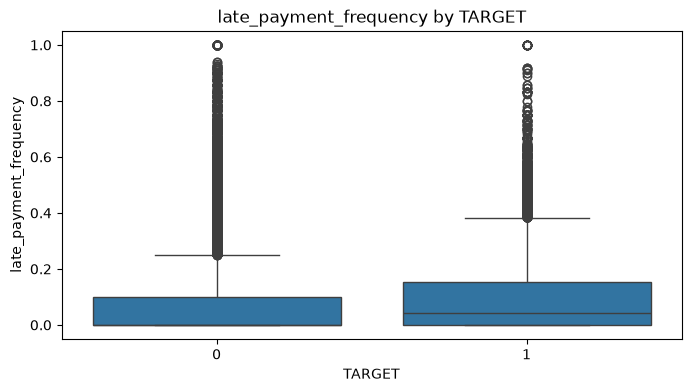

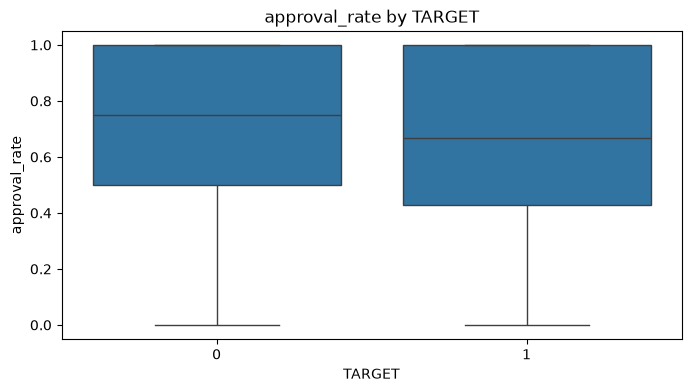

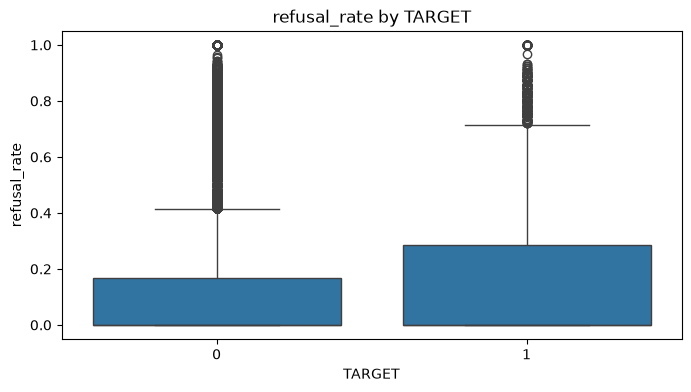

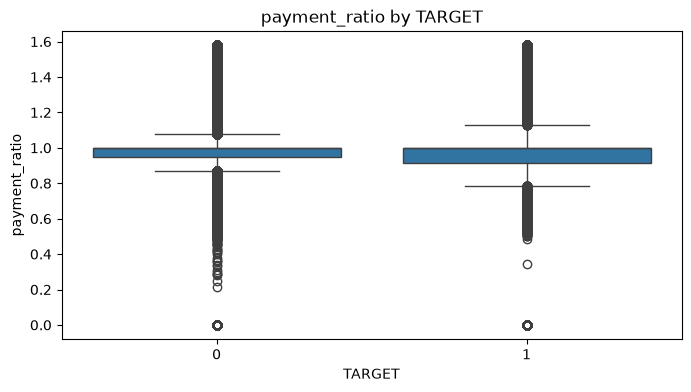

In [30]:
key_features = [
    'dpd_frequency', 'overdue_frequency', 'late_payment_frequency',
    'approval_rate', 'refusal_rate', 'payment_ratio'
]

for col in key_features:
    plt.figure(figsize=(8, 4))
    sns.boxplot(data=train_df, x='TARGET', y=col)
    plt.title(f'{col} by TARGET')
    plt.show()

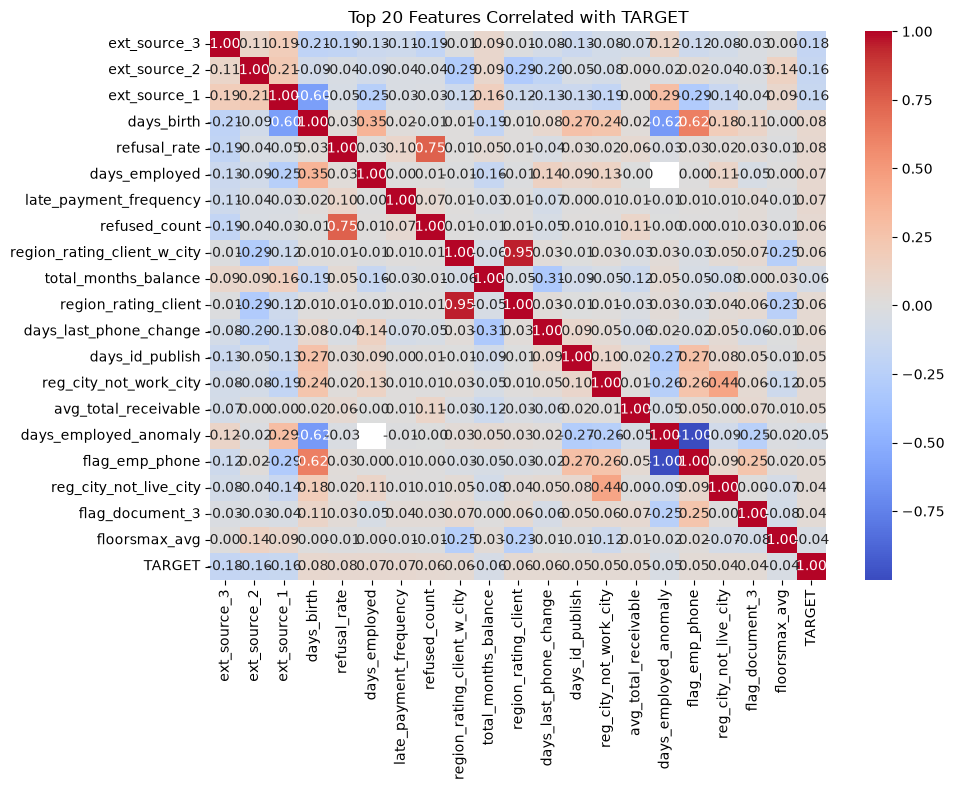

In [31]:
numeric_cols = train_df.select_dtypes(include='number').columns
target_corr = train_df[numeric_cols].corr()['TARGET'].drop('TARGET')

top_n = 20
top_features = target_corr.abs().sort_values(ascending=False).head(top_n).index

plt.figure(figsize=(10, 8))
sns.heatmap(train_df[top_features.tolist() + ['TARGET']].corr(), 
            cmap='coolwarm', center=0, annot=True, fmt='.2f')
plt.title(f'Top {top_n} Features Correlated with TARGET')
plt.tight_layout()
plt.show()

In [32]:
import numpy as np
corr_matrix = train_df[numeric_cols].corr().abs()

# Yalnız üst üçbucağı götür (təkrarları aradan qaldırmaq üçün)
upper = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

high_corr_pairs = upper.stack().sort_values(ascending=False)
high_corr_pairs = high_corr_pairs[high_corr_pairs > 0.75]

print(high_corr_pairs)

flag_emp_phone                days_employed_anomaly           0.999868
total_credit_limit            max_credit_limit                0.999073
years_build_avg               years_build_medi                0.998495
obs_30_cnt_social_circle      obs_60_cnt_social_circle        0.998491
floorsmin_avg                 floorsmin_medi                  0.997241
floorsmax_avg                 floorsmax_medi                  0.997034
entrances_avg                 entrances_medi                  0.996886
elevators_avg                 elevators_medi                  0.996099
commonarea_avg                commonarea_medi                 0.995978
livingarea_avg                livingarea_medi                 0.995596
apartments_avg                apartments_medi                 0.995081
basementarea_avg              basementarea_medi               0.994317
livingapartments_avg          livingapartments_medi           0.993825
years_beginexpluatation_avg   years_beginexpluatation_medi    0.993825
landar

In [33]:
train_df.shape

(307511, 178)

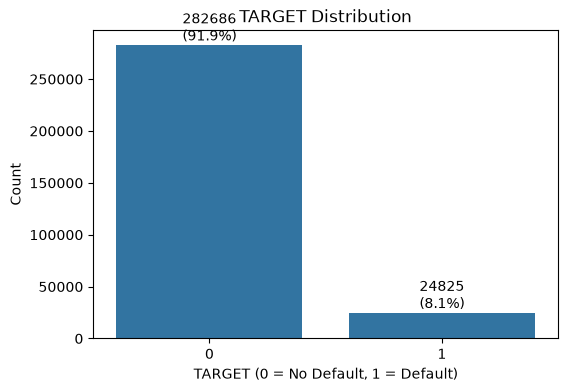

In [34]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))
ax = sns.countplot(x='TARGET', data=train_df)

total = len(train_df)
for p in ax.patches:
    count = int(p.get_height())
    pct = 100 * count / total
    ax.annotate(f'{count}\n({pct:.1f}%)',
                (p.get_x() + p.get_width() / 2, p.get_height()),
                ha='center', va='bottom')

plt.title('TARGET Distribution')
plt.xlabel('TARGET (0 = No Default, 1 = Default)')
plt.ylabel('Count')
plt.show()

## EXT_SOURCE_2 vs EXT_SOURCE_3 by TARGET

Scatter plot shows the relationship between two external credit scoring
sources, colored by default status (`TARGET`).

**Key observation:** Orange points (`TARGET = 1`, defaulted customers) are
visibly concentrated in the bottom-left region, where both `EXT_SOURCE_2`
and `EXT_SOURCE_3` are low. Blue points (`TARGET = 0`) dominate the
upper-right region. This confirms that customers with low scores on both
external sources carry substantially higher default risk — validating
these two features as strong predictors for the model.

**Note on artifacts:** The horizontal band around `EXT_SOURCE_3 ≈ 0.53`
reflects median imputation applied to missing values in that column, not
an underlying pattern in the data.


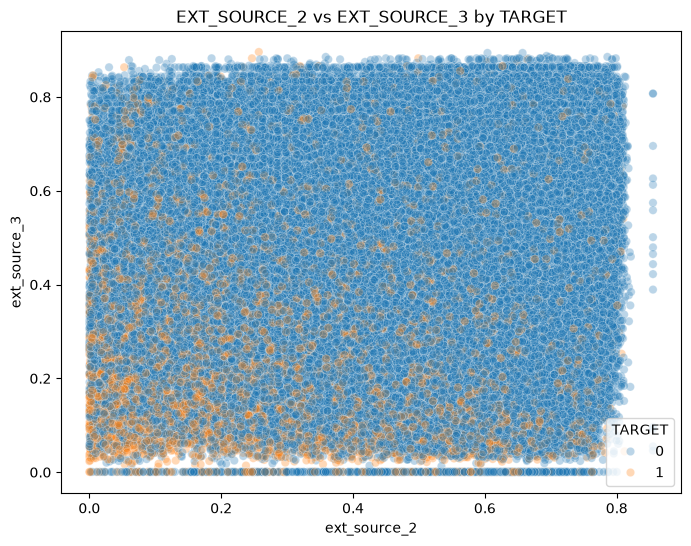

In [35]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=train_df, x='ext_source_2', y='ext_source_3', hue='TARGET', alpha=0.3)
plt.title('EXT_SOURCE_2 vs EXT_SOURCE_3 by TARGET')
plt.show()

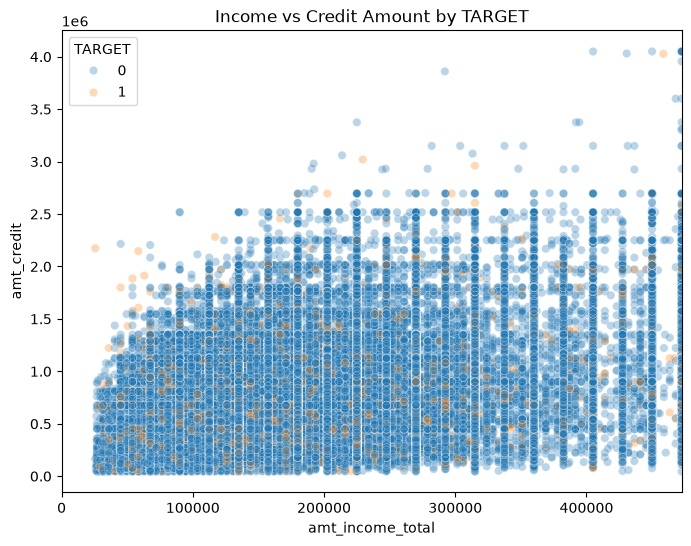

In [36]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=train_df, x='amt_income_total', y='amt_credit', hue='TARGET', alpha=0.3)
plt.xlim(0, train_df['amt_income_total'].quantile(0.99))  # outlier-ləri kəsib görüntünü aydınlaşdırır
plt.title('Income vs Credit Amount by TARGET')
plt.show()

## Payment Ratio vs DPD Frequency by TARGET

Scatter plot showing the relationship between customers' payment ratio
(`payment_ratio`) and delinquency frequency (`dpd_frequency`), colored by
default status (`TARGET`).

**Key observation:** Most points cluster in a dense vertical band around
`payment_ratio ≈ 1.0`, indicating that the majority of customers pay
close to the scheduled amount. Unlike the `EXT_SOURCE` plot, there is no
clear separation between classes here — orange (`TARGET = 1`) and blue
(`TARGET = 0`) points are mixed throughout most of the region. This
suggests that `payment_ratio` and `dpd_frequency` are not strongly
discriminative on their own, but may still contribute complementary
signal when combined with other features in the model.

**Note:** The dense line of points at `payment_ratio = 0` is an artifact
of the `fillna(0)` imputation applied to customers with no installment
history.

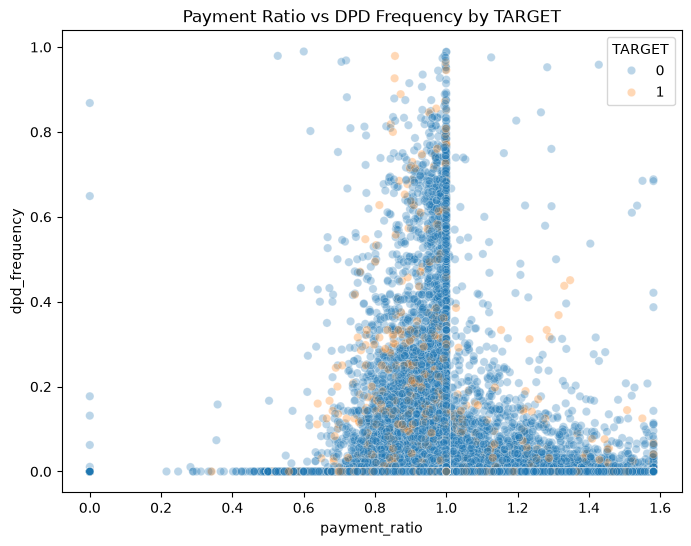

In [37]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=train_df, x='payment_ratio', y='dpd_frequency', hue='TARGET', alpha=0.3)
plt.title('Payment Ratio vs DPD Frequency by TARGET')
plt.show()

In [38]:

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", None)

display(train_df.head())

,sk_id_curr,TARGET,name_contract_type,code_gender,flag_own_car,flag_own_realty,cnt_children,amt_income_total,amt_credit,amt_annuity,amt_goods_price,name_type_suite,name_income_type,name_education_type,name_family_status,name_housing_type,region_population_relative,days_birth,days_employed,days_registration,days_id_publish,own_car_age,flag_mobil,flag_emp_phone,flag_work_phone,flag_cont_mobile,flag_phone,flag_email,occupation_type,cnt_fam_members,region_rating_client,region_rating_client_w_city,weekday_appr_process_start,hour_appr_process_start,reg_region_not_live_region,reg_region_not_work_region,live_region_not_work_region,reg_city_not_live_city,reg_city_not_work_city,live_city_not_work_city,organization_type,ext_source_1,ext_source_2,ext_source_3,apartments_avg,basementarea_avg,years_beginexpluatation_avg,years_build_avg,commonarea_avg,elevators_avg,entrances_avg,floorsmax_avg,floorsmin_avg,landarea_avg,livingapartments_avg,livingarea_avg,nonlivingapartments_avg,nonlivingarea_avg,apartments_mode,basementarea_mode,years_beginexpluatation_mode,years_build_mode,commonarea_mode,elevators_mode,entrances_mode,floorsmax_mode,floorsmin_mode,landarea_mode,livingapartments_mode,livingarea_mode,nonlivingapartments_mode,nonlivingarea_mode,apartments_medi,basementarea_medi,years_beginexpluatation_medi,years_build_medi,commonarea_medi,elevators_medi,entrances_medi,floorsmax_medi,floorsmin_medi,landarea_medi,livingapartments_medi,livingarea_medi,nonlivingapartments_medi,nonlivingarea_medi,fondkapremont_mode,housetype_mode,totalarea_mode,wallsmaterial_mode,emergencystate_mode,obs_30_cnt_social_circle,def_30_cnt_social_circle,obs_60_cnt_social_circle,def_60_cnt_social_circle,days_last_phone_change,flag_document_2,flag_document_3,flag_document_4,flag_document_5,flag_document_6,flag_document_7,flag_document_8,flag_document_9,flag_document_10,flag_document_11,flag_document_12,flag_document_13,flag_document_14,flag_document_15,flag_document_16,flag_document_17,flag_document_18,flag_document_19,flag_document_20,flag_document_21,amt_req_credit_bureau_hour,amt_req_credit_bureau_day,amt_req_credit_bureau_week,amt_req_credit_bureau_mon,amt_req_credit_bureau_qrt,amt_req_credit_bureau_year,card_count,total_months_balance,total_credit_limit,max_credit_limit,avg_atm_drawings,avg_drawings,total_drawings,avg_min_regularity,avg_payment,avg_total_receivable,max_dpd,max_dpd_def,dpd_month_count,dpd_def_month_count,dpd_frequency,dpd_def_frequency,bureau_credit_count,active_credit_count,closed_credit_count,total_credit_sum,total_debt,max_credit_sum,avg_credit_sum,max_credit_day_overdue,total_credit_day_overdue,total_observation_months,total_overdue_months,overdue_frequency,max_status,installment_credit_count,total_installment_count,total_installment_amount,total_payment_amount,payment_ratio,total_late_days,max_late_days,avg_late_days,late_installment_count,late_payment_frequency,underpaid_installment_count,fully_paid_installment_count,total_payment_gap,previous_application_count,approved_count,refused_count,approval_rate,refusal_rate,max_approved_credit,avg_approved_credit,min_refused_credit,max_approved_annuity,avg_approved_annuity,latest_previous_application,avg_previous_credit,days_employed_anomaly,amt_income_total_log
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,351000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.018801,-9461,-637.0,-3648.0,-2120,NaN,1,1,0,1,1,0,Laborers,1.0,2,2,WEDNESDAY,10,0,0,0,0,0,0,Business Entity Type 3,0.083037,0.262949,0.139376,0.0247,0.0369,0.9722,0.6192,0.0143,0.00,0.0690,0.0833,0.1250,0.0369,0.0202,0.0190,0.0000,0.0000,0.0252,0.0383,0.9722,0.6341,0.0144,0.0000,0.0690,0.0833,0.1250,0.0377,0.022,0.0198,0.0,0.0,0.0250,0.0369,0.9722,0.6243,0.0144,0.00,0.0690,0.0833,0.1250,0.0375,0.0205,0.0193,0.0000,0.00,reg oper account,block of flats,0.0149,"Stone, brick",No,2.0,2.0,2.0,2.0,-1134.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,NaN,0.0,0.0,0.0,0.0,0.0,0

In [39]:
flag_cols = [c for c in train_df.columns if c.startswith('flag_document_')]

doc_stats = pd.DataFrame({
    'column': flag_cols,
    'ones': [train_df[c].sum() for c in flag_cols],
    'ones_rate': [train_df[c].mean() for c in flag_cols]
}).sort_values('ones_rate')

display(doc_stats)

,column,ones,ones_rate
10,flag_document_12,2,0.000007
8,flag_document_10,7,0.000023
0,flag_document_2,13,0.000042
2,flag_document_4,25,0.000081
5,flag_document_7,59,0.000192
15,flag_document_17,82,0.000267
19,flag_document_21,103,0.000335
18,flag_document_20,156,0.000507
17,flag_document_19,183,0.000595
13,flag_document_15,372,0.001210


### FLAG_DOCUMENT Features

The `FLAG_DOCUMENT_*` variables are binary features (`0` and `1`) indicating whether certain types of documents were provided during the application process.

During feature selection, the **frequency of the `1` value** for each variable was analyzed. Some `FLAG_DOCUMENT_*` features had extremely low occurrence rates, meaning that the value `1` was observed in only a very small number of applications.

These features were removed for the following reasons:

* The occurrence rate of the `1` value was extremely low.
* Such a small number of observations can lead to unstable patterns in the model.
* The predictive contribution of extremely rare features is difficult to estimate reliably.
* Removing these features helps reduce the dimensionality of the dataset and makes the final feature set simpler and more interpretable.

Therefore, **`FLAG_DOCUMENT_*` variables with extremely low occurrence rates were removed from the feature set**, while document flags with sufficiently frequent observations were retained.

> **Note:** A low occurrence rate does not necessarily mean that a feature is useless. Therefore, the final decision should ideally be validated using cross-validation and model performance metrics.


In [40]:

drop_document = [
    'flag_document_12',
    'flag_document_10',
    'flag_document_2',
    'flag_document_4',
    'flag_document_7',
    'flag_document_17',
    'flag_document_21',
    'flag_document_20',
    'flag_document_19',
    'flag_document_15',
    'flag_document_14',
    'flag_document_13',
    'flag_document_9',
    'flag_document_11',
    'flag_document_16',
    'flag_document_18',
    #'flag_document_5'
]
train_df=train_df.drop(columns=drop_document)



In [41]:
train_df.shape

(307511, 162)

In [42]:
import pandas as pd
pd.set_option('display.max_rows', None)

from IPython.display import display

missing = train_df.isnull().sum()
missing_pct = (missing / len(train_df)) * 100

missing_df = pd.DataFrame({
    'column': missing.index,
    'missing_count': missing.values,
    'missing_pct': missing_pct.values.round(2)
})

missing_df = missing_df.sort_values('missing_pct', ascending=False).reset_index(drop=True)

display(missing_df)

,column,missing_count,missing_pct
0,total_months_balance,220606,71.74
1,max_status,215280,70.01
2,commonarea_medi,214865,69.87
3,commonarea_mode,214865,69.87
4,commonarea_avg,214865,69.87
5,nonlivingapartments_medi,213514,69.43
6,nonlivingapartments_mode,213514,69.43
7,nonlivingapartments_avg,213514,69.43
8,fondkapremont_mode,210295,68.39
9,livingapartments_medi,210199,68.35


## `Feature engineering`

In [43]:
train_df['has_bureau_balance_history'] = train_df['max_status'].notna().astype(int)
train_df['max_status'] = train_df['max_status'].fillna(0)

/var/folders/yt/vzj07vbd1gv2mjpzwt562v_m0000gn/T/ipykernel_47781/904142492.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  train_df['has_bureau_balance_history'] = train_df['max_status'].notna().astype(int)


In [ ]:
train_df['has_ext_source_1'] = train_df['ext_source_1'].notna().astype(int)
train_df['has_ext_source_3'] = train_df['ext_source_3'].notna().astype(int)

/var/folders/yt/vzj07vbd1gv2mjpzwt562v_m0000gn/T/ipykernel_47781/866638503.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  train_df['has_ext_source_1'] = train_df['ext_source_1'].notna().astype(int)
/var/folders/yt/vzj07vbd1gv2mjpzwt562v_m0000gn/T/ipykernel_47781/866638503.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  train_df['has_ext_source_3'] = train_df['ext_source_3'].notna().astype(int)


---------------------------------------------------------------------------------------------

## `annual_debt_ratio`

In [45]:
# Ratio of monthly annuity payment to monthly income (debt burden indicator)
train_df['annual_debt_ratio'] = train_df['amt_annuity'] / train_df['amt_income_total']


/var/folders/yt/vzj07vbd1gv2mjpzwt562v_m0000gn/T/ipykernel_47781/1568470839.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  train_df['annual_debt_ratio'] = train_df['amt_annuity'] / train_df['amt_income_total']


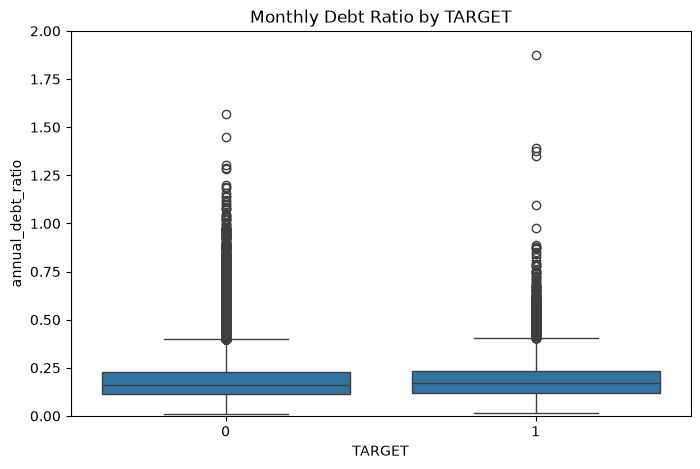

In [46]:
import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 5))
sns.boxplot(data=train_df, x='TARGET', y='annual_debt_ratio')
plt.ylim(0, 2)  # ekstremal outlier-ləri kənarda qoyub əsas hissəni aydın görmək üçün
plt.title('Monthly Debt Ratio by TARGET')
plt.show()

In [47]:
from scipy.stats import mannwhitneyu

g0 = train_df[train_df['TARGET']==0]['annual_debt_ratio'].dropna()
g1 = train_df[train_df['TARGET']==1]['annual_debt_ratio'].dropna()

stat, p = mannwhitneyu(g0, g1)
print(f'p-value: {p}')
print(f'Median (TARGET=0): {g0.median()}')
print(f'Median (TARGET=1): {g1.median()}')

p-value: 2.3118071242034223e-23
Median (TARGET=0): 0.162375
Median (TARGET=1): 0.16935


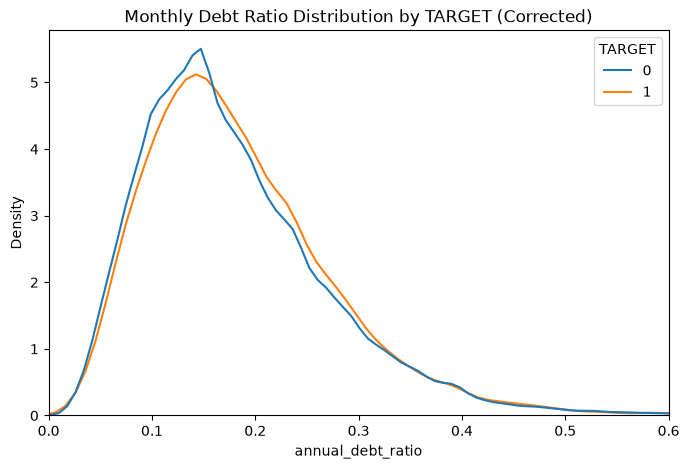

In [48]:
plt.figure(figsize=(8, 5))
sns.kdeplot(data=train_df, x='annual_debt_ratio', hue='TARGET', common_norm=False)
plt.xlim(0, 0.6)
plt.title('Monthly Debt Ratio Distribution by TARGET (Corrected)')
plt.show()

`annual_debt_ratio` — Weak but Statistically Significant Signal

**Result:** Medians are 0.162 (TARGET=0) vs 0.169 (TARGET=1) — a small
but statistically significant difference (p ≈ 2.3e-23), consistent with
the direction expected (higher debt burden associated with default),
though the practical effect size is modest.

---------------------------------------------------------------------------------------------

In [49]:
train_df['age_years'] = (train_df['days_birth'] / 365) * (-1)

/var/folders/yt/vzj07vbd1gv2mjpzwt562v_m0000gn/T/ipykernel_47781/472011185.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  train_df['age_years'] = (train_df['days_birth'] / 365) * (-1)


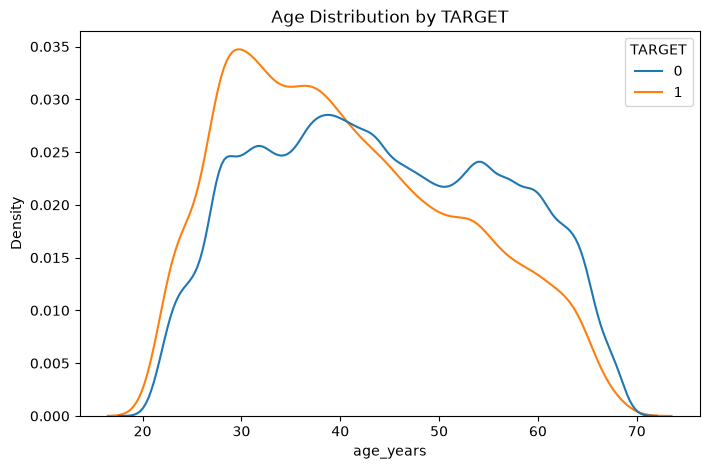

In [50]:
import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 5))
sns.kdeplot(data=train_df, x='age_years', hue='TARGET', common_norm=False)
plt.title('Age Distribution by TARGET')
plt.show()

In [ ]:
housing_avg_cols = [
    'apartments_avg', 'basementarea_avg', 'years_beginexpluatation_avg',
    'years_build_avg', 'commonarea_avg', 'elevators_avg', 'entrances_avg',
    'floorsmax_avg', 'floorsmin_avg', 'landarea_avg', 'livingapartments_avg',
    'livingarea_avg', 'nonlivingapartments_avg', 'nonlivingarea_avg'
]

train_df['housing_quality_score'] = train_df[housing_avg_cols].mean(axis=1)
train_df['has_housing_info'] = train_df['housing_quality_score'].notna().astype(int)
train_df['housing_quality_score'] = train_df['housing_quality_score'].fillna(0)



/var/folders/yt/vzj07vbd1gv2mjpzwt562v_m0000gn/T/ipykernel_47781/648684629.py:8: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  train_df['housing_quality_score'] = train_df[housing_avg_cols].mean(axis=1)
/var/folders/yt/vzj07vbd1gv2mjpzwt562v_m0000gn/T/ipykernel_47781/648684629.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  train_df['has_housing_info'] = train_df['housing_quality_score'].notna().astype(int)


In [ ]:
train_df['owns_realty'] = train_df['flag_own_realty'].map({'Y': 1, 'N': 0})


/var/folders/yt/vzj07vbd1gv2mjpzwt562v_m0000gn/T/ipykernel_47781/773922125.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  train_df['owns_realty'] = train_df['flag_own_realty'].map({'Y': 1, 'N': 0})


**Note:** `owns_realty` and `has_housing_info` answer different
questions — the former reflects whether the customer owns any real
estate (`flag_own_realty`), while the latter reflects whether detailed
information about their *current residence* was available in the
housing columns. A customer can own property elsewhere while their
current residence details are missing, so `owns_realty = 1` and
`has_housing_info = 0` occurring together is expected, not an error.

In [53]:
count = ((train_df['owns_realty'] == 1) & (train_df['has_housing_info'] == 0)).sum()
print(count)

101736


In [ ]:
train_df['owns_car'] = train_df['flag_own_car'].map({'Y': 1, 'N': 0})


/var/folders/yt/vzj07vbd1gv2mjpzwt562v_m0000gn/T/ipykernel_47781/2948089603.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  train_df['owns_car'] = train_df['flag_own_car'].map({'Y': 1, 'N': 0})


In [55]:
# Find all flag_document_ columns and sum them into a total document count,
# then drop the now-redundant individual document columns
doc_cols = [c for c in train_df.columns if c.startswith('flag_document_')]
train_df['document_count'] = train_df[doc_cols].sum(axis=1)
train_df = train_df.drop(columns=doc_cols)

/var/folders/yt/vzj07vbd1gv2mjpzwt562v_m0000gn/T/ipykernel_47781/355065257.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  train_df['document_count'] = train_df[doc_cols].sum(axis=1)


In [56]:
print(train_df['document_count'].corr(train_df['TARGET']))

0.03184644995813484


In [57]:
# Compute mean, std  across the three external credit scores
ext_cols = ['ext_source_1', 'ext_source_2', 'ext_source_3']
train_df['ext_source_mean'] = train_df[ext_cols].mean(axis=1)
train_df['ext_source_std'] = train_df[ext_cols].std(axis=1)


/var/folders/yt/vzj07vbd1gv2mjpzwt562v_m0000gn/T/ipykernel_47781/385484071.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  train_df['ext_source_mean'] = train_df[ext_cols].mean(axis=1)
/var/folders/yt/vzj07vbd1gv2mjpzwt562v_m0000gn/T/ipykernel_47781/385484071.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  train_df['ext_source_std'] = train_df[ext_cols].std(axis=1)


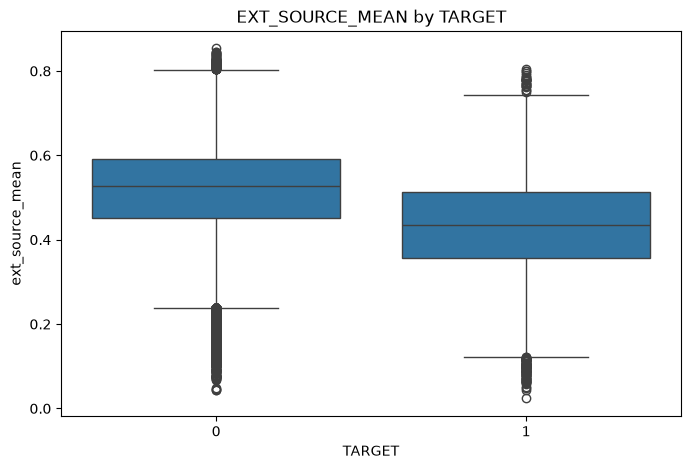

In [58]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=train_df, x='TARGET', y='ext_source_mean')
plt.title('EXT_SOURCE_MEAN by TARGET')
plt.show()

In [59]:
# Compute income per family member and the share of children within the family
train_df['income_per_family_member'] = train_df['amt_income_total'] / train_df['cnt_fam_members']
train_df['children_ratio'] = train_df['cnt_children'] / train_df['cnt_fam_members']

/var/folders/yt/vzj07vbd1gv2mjpzwt562v_m0000gn/T/ipykernel_47781/1751283431.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  train_df['income_per_family_member'] = train_df['amt_income_total'] / train_df['cnt_fam_members']
/var/folders/yt/vzj07vbd1gv2mjpzwt562v_m0000gn/T/ipykernel_47781/1751283431.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  train_df['children_ratio'] = train_df['cnt_children'] / train_df['cnt_fam_members']


In [60]:
# Count the number of verified contact methods (phone, email, etc.),
# then drop the now-redundant individual contact columns
contact_cols = ['flag_phone', 'flag_email', 'flag_cont_mobile', 'flag_work_phone']
train_df['contact_completeness'] = train_df[contact_cols].sum(axis=1)


/var/folders/yt/vzj07vbd1gv2mjpzwt562v_m0000gn/T/ipykernel_47781/2212397358.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  train_df['contact_completeness'] = train_df[contact_cols].sum(axis=1)


In [61]:
train_df['closed_credit_rate'] = (
    train_df['closed_credit_count'] /
    train_df['bureau_credit_count'].replace(0, np.nan)
)
train_df['closed_credit_rate'] = train_df['closed_credit_rate'].fillna(0)


/var/folders/yt/vzj07vbd1gv2mjpzwt562v_m0000gn/T/ipykernel_47781/3791951218.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  train_df['closed_credit_rate'] = (


---------------------------------------------------------------------------------------------

### `credit_health_score`

In [62]:
# Combine several risk indicators (closed credits, delinquency, approval rate)
# into a single weighted "credit health" score
train_df['credit_health_score'] = (
    train_df['closed_credit_rate'].fillna(0) * 0.3 +
    (1 - train_df['dpd_frequency'].fillna(0)) * 0.3 +
    (1 - train_df['late_payment_frequency'].fillna(0)) * 0.2 +
    train_df['approval_rate'].fillna(0) * 0.2
)

/var/folders/yt/vzj07vbd1gv2mjpzwt562v_m0000gn/T/ipykernel_47781/4182220328.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  train_df['credit_health_score'] = (




**Result:** Medians are 0.791 (TARGET=0) vs 0.724 (TARGET=1) — a
Mann-Whitney U test confirms this difference is statistically
significant (p ≈ 0), not an artifact of class imbalance or KDE
smoothing on the smaller group. Customers who defaulted show a
meaningfully lower credit health score, consistent with the intended
design of the composite feature.

In [63]:
from scipy.stats import mannwhitneyu

group0 = train_df[train_df['TARGET'] == 0]['credit_health_score']
group1 = train_df[train_df['TARGET'] == 1]['credit_health_score']

stat, p_value = mannwhitneyu(group0, group1)
print(f'p-value: {p_value}')
print(f'Median (TARGET=0): {group0.median()}')
print(f'Median (TARGET=1): {group1.median()}')

p-value: 0.0
Median (TARGET=0): 0.7914113098952915
Median (TARGET=1): 0.724074074074074


## Credit Health Score Distribution by TARGET

**Key observation:** The distribution for `TARGET = 0` (non-defaulters,
blue) is shifted noticeably to the right, with more density concentrated
in the 0.8–1.0 range. The `TARGET = 1` distribution (defaulters, orange)
is shifted left, concentrated more around 0.5–0.75. This confirms the
composite score behaves as intended — customers with a healthier credit
history show a meaningfully different score distribution than those who
defaulted.

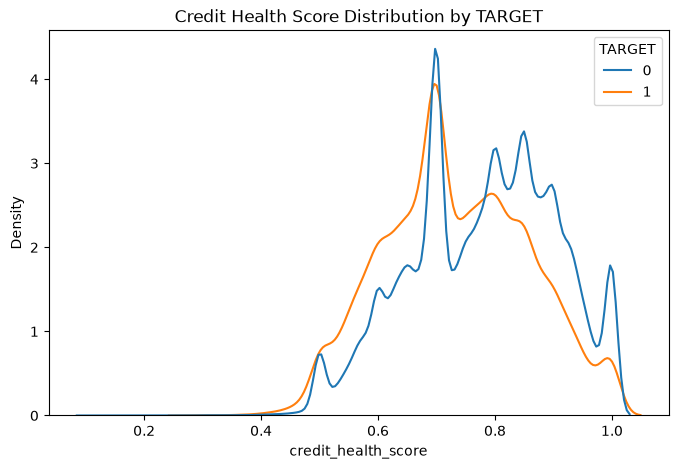

In [64]:
plt.figure(figsize=(8, 5))
sns.kdeplot(data=train_df, x='credit_health_score', hue='TARGET', common_norm=False)
plt.title('Credit Health Score Distribution by TARGET')
plt.show()

In [65]:
# Sum the customer's total financial activity (bureau, credit card, and
# previous applications) and normalize by age to get activity density
# per year of life, then drop the now-redundant days_birth column
train_df['financial_activity_density'] = (
    train_df['bureau_credit_count'].fillna(0) + 
    train_df['card_count'].fillna(0) + 
    train_df['previous_application_count'].fillna(0)
) / (-train_df['days_birth'] / 365) 
train_df = train_df.drop(columns='days_birth')

/var/folders/yt/vzj07vbd1gv2mjpzwt562v_m0000gn/T/ipykernel_47781/3244866697.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  train_df['financial_activity_density'] = (


In [66]:
# Combine address mismatch flags (registration vs. living/working location)
# with the regional risk rating into a single "address instability" score,
# then drop the now-redundant individual mismatch columns
mismatch_cols = ['reg_region_not_live_region', 'reg_region_not_work_region', 
                  'reg_city_not_live_city', 'reg_city_not_work_city']
train_df['address_instability_score'] = train_df[mismatch_cols].sum(axis=1) * train_df['region_rating_client_w_city']


/var/folders/yt/vzj07vbd1gv2mjpzwt562v_m0000gn/T/ipykernel_47781/3636541509.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  train_df['address_instability_score'] = train_df[mismatch_cols].sum(axis=1) * train_df['region_rating_client_w_city']


In [67]:
train_df['credit_goods_ratio'] = (
    train_df['amt_credit'] / train_df['amt_goods_price']
)


/var/folders/yt/vzj07vbd1gv2mjpzwt562v_m0000gn/T/ipykernel_47781/1703025760.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  train_df['credit_goods_ratio'] = (


In [68]:
train_df['monthly_drawing_avg'] = (
    train_df['total_drawings'] /
    train_df['total_months_balance'].replace(0, np.nan)
).fillna(0)


/var/folders/yt/vzj07vbd1gv2mjpzwt562v_m0000gn/T/ipykernel_47781/3609816122.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  train_df['monthly_drawing_avg'] = (


In [69]:
train_df['approval_rate'] = (
    train_df['approved_count'] /
    train_df['previous_application_count'].replace(0, np.nan)
).fillna(0)

In [70]:
train_df['current_vs_previous_credit'] = (
    train_df['amt_credit'] /
    train_df['avg_approved_credit'].replace(0, np.nan)
).fillna(0)

/var/folders/yt/vzj07vbd1gv2mjpzwt562v_m0000gn/T/ipykernel_47781/722506197.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  train_df['current_vs_previous_credit'] = (


In [71]:
train_df['family_debt_pressure'] = train_df['annual_debt_ratio'] / (train_df['income_per_family_member'] + 1)

/var/folders/yt/vzj07vbd1gv2mjpzwt562v_m0000gn/T/ipykernel_47781/402379599.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  train_df['family_debt_pressure'] = train_df['annual_debt_ratio'] / (train_df['income_per_family_member'] + 1)


In [72]:
train_df['realty_age_mismatch'] = train_df['owns_realty'] / (train_df['age_years'] + 1)

/var/folders/yt/vzj07vbd1gv2mjpzwt562v_m0000gn/T/ipykernel_47781/4204438952.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  train_df['realty_age_mismatch'] = train_df['owns_realty'] / (train_df['age_years'] + 1)


In [73]:
train_df['stability_score'] = (
    train_df['owns_car'] + 
    train_df['owns_realty'] + 
    train_df['has_housing_info']
)
col=['owns_car','owns_realty','has_housing_info']


/var/folders/yt/vzj07vbd1gv2mjpzwt562v_m0000gn/T/ipykernel_47781/3238995411.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  train_df['stability_score'] = (


In [74]:
train_df['confidence_adjusted_health'] = train_df['credit_health_score'] * (1 - train_df['ext_source_std'])

/var/folders/yt/vzj07vbd1gv2mjpzwt562v_m0000gn/T/ipykernel_47781/2261181164.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  train_df['confidence_adjusted_health'] = train_df['credit_health_score'] * (1 - train_df['ext_source_std'])


In [75]:
train_df['instability_experience_ratio'] = (
    train_df['address_instability_score'] / (train_df['financial_activity_density'] + 0.01)
)

/var/folders/yt/vzj07vbd1gv2mjpzwt562v_m0000gn/T/ipykernel_47781/1233293767.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  train_df['instability_experience_ratio'] = (


In [76]:
train_df['instability_experience_ratio'].corr(train_df['TARGET'])

np.float64(0.029667339384554396)

In [77]:
import pandas as pd
pd.set_option('display.max_rows', None)

from IPython.display import display

missing = train_df.isnull().sum()
missing_pct = (missing / len(train_df)) * 100

missing_df = pd.DataFrame({
    'column': missing.index,
    'missing_count': missing.values,
    'missing_pct': missing_pct.values.round(2)
})

missing_df = missing_df.sort_values('missing_pct', ascending=False).reset_index(drop=True)

display(missing_df)

,column,missing_count,missing_pct
0,total_months_balance,220606,71.74
1,commonarea_medi,214865,69.87
2,commonarea_mode,214865,69.87
3,commonarea_avg,214865,69.87
4,nonlivingapartments_medi,213514,69.43
5,nonlivingapartments_mode,213514,69.43
6,nonlivingapartments_avg,213514,69.43
7,fondkapremont_mode,210295,68.39
8,livingapartments_mode,210199,68.35
9,livingapartments_avg,210199,68.35


In [78]:
print(train_df.isnull().sum().sum())  # ümumi NULL sayı
print(train_df['amt_annuity'].isnull().sum())
print(train_df['cnt_fam_members'].isnull().sum())

8984573
12
2


In [79]:
null_ratio = train_df.isnull().mean()

cols_to_drop = null_ratio[null_ratio >= 0.40].index

train_df = train_df.drop(columns=cols_to_drop)

In [80]:
train_df.shape

(307511, 135)

In [81]:
numeric_cols = train_df.select_dtypes(include='number').columns.tolist()
categorical_cols = train_df.select_dtypes(include=['object', 'category']).columns.tolist()

print(f"Numeric columns ({len(numeric_cols)}):")
print(numeric_cols)

print(f"\nCategorical columns ({len(categorical_cols)}):")
print(categorical_cols)

Numeric columns (123):
['sk_id_curr', 'TARGET', 'cnt_children', 'amt_income_total', 'amt_credit', 'amt_annuity', 'amt_goods_price', 'region_population_relative', 'days_employed', 'days_registration', 'days_id_publish', 'flag_mobil', 'flag_emp_phone', 'flag_work_phone', 'flag_cont_mobile', 'flag_phone', 'flag_email', 'cnt_fam_members', 'region_rating_client', 'region_rating_client_w_city', 'hour_appr_process_start', 'reg_region_not_live_region', 'reg_region_not_work_region', 'live_region_not_work_region', 'reg_city_not_live_city', 'reg_city_not_work_city', 'live_city_not_work_city', 'ext_source_1', 'ext_source_2', 'ext_source_3', 'obs_30_cnt_social_circle', 'def_30_cnt_social_circle', 'obs_60_cnt_social_circle', 'def_60_cnt_social_circle', 'days_last_phone_change', 'amt_req_credit_bureau_hour', 'amt_req_credit_bureau_day', 'amt_req_credit_bureau_week', 'amt_req_credit_bureau_mon', 'amt_req_credit_bureau_qrt', 'amt_req_credit_bureau_year', 'card_count', 'total_credit_limit', 'max_credit_

/var/folders/yt/vzj07vbd1gv2mjpzwt562v_m0000gn/T/ipykernel_47781/841625027.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = train_df.select_dtypes(include=['object', 'category']).columns.tolist()


In [82]:
for col in train_df.columns:
    if train_df[col].isnull().sum() > 0:
        if train_df[col].dtype in ['int64', 'float64']:
            # Nümərik sütun -> 0 ilə doldur
            train_df[col] = train_df[col].fillna(0)
        else:
            # Kateqorik sütun -> mode (ən çox rast gəlinən dəyər) ilə doldur
            mode_val = train_df[col].mode()[0]
            train_df[col] = train_df[col].fillna(mode_val)
          

In [83]:
train_df_lr = train_df


In [84]:
train_df_lr=train_df_lr.drop(columns='sk_id_curr')

In [85]:
df_for_treemodel=train_df

In [120]:
df_for_treemodel=df_for_treemodel.drop(columns='sk_id_curr')

In [86]:
train_df.select_dtypes(exclude='number').dtypes

name_contract_type            str
code_gender                   str
flag_own_car                  str
flag_own_realty               str
name_type_suite               str
name_income_type              str
name_education_type           str
name_family_status            str
name_housing_type             str
occupation_type               str
weekday_appr_process_start    str
organization_type             str
dtype: object

In [87]:
train_df['name_income_type'].unique()

<StringArray>
[             'Working',        'State servant', 'Commercial associate',
            'Pensioner',           'Unemployed',              'Student',
          'Businessman',      'Maternity leave']
Length: 8, dtype: str

In [88]:
from sklearn.model_selection import train_test_split

X = df_for_treemodel.drop(columns='TARGET')
y = df_for_treemodel['TARGET']

# 1-ci bölgü (sizin mövcud kodunuz - olduğu kimi qalır)
x_dev, x_test, y_dev, y_test = train_test_split(
    X,
    y,
    test_size=0.06,
    random_state=42,
    stratify=y
)

# 2-ci bölgü - x_dev-i YENİDƏN bölürük (threshold üçün val ayırmaq üçün)
x_dev, x_val, y_dev, y_val = train_test_split(
    x_dev,
    y_dev,
    test_size=0.10,
    random_state=42,
    stratify=y_dev
)

print('x_dev (təlim + tuning):', x_dev.shape)
print('x_val (threshold üçün):', x_val.shape)
print('x_test (yekun qiymətləndirmə):', x_test.shape)

x_dev (təlim + tuning): (260154, 134)
x_val (threshold üçün): (28906, 134)
x_test (yekun qiymətləndirmə): (18451, 134)


In [89]:
from sklearn.model_selection import train_test_split

X = train_df_lr.drop(columns='TARGET')
y = train_df_lr['TARGET']

x_dev_lr, x_test_lr, y_dev_lr, y_test_lr = train_test_split(
    X,
    y,
    test_size=0.06,
    random_state=42,
    stratify=y
)

print('x_dev_lr:', x_dev_lr.shape)
print('x_test_lr:', x_test_lr.shape)

x_dev_lr: (289060, 133)
x_test_lr: (18451, 133)


In [90]:
# Categorical columns
categorical_cols = x_dev_lr.select_dtypes(
    include=["object", "category"]
).columns

# Numerical columns
numerical_cols = x_dev_lr.select_dtypes(
    include=["number"]
).columns


# ==============================
# DEV DATA
# ==============================

# Mode values from DEV
dev_modes = x_dev_lr[categorical_cols].mode().iloc[0]

# Median values from DEV
dev_medians = x_dev_lr[numerical_cols].median()


# Fill DEV
x_dev_lr[categorical_cols] = x_dev_lr[categorical_cols].fillna(dev_modes)
x_dev_lr[numerical_cols] = x_dev_lr[numerical_cols].fillna(dev_medians)


# ==============================
# TEST DATA
# ==============================

# Fill TEST using DEV statistics
x_test_lr[categorical_cols] = x_test_lr[categorical_cols].fillna(dev_modes)
x_test_lr[numerical_cols] = x_test_lr[numerical_cols].fillna(dev_medians)

/var/folders/yt/vzj07vbd1gv2mjpzwt562v_m0000gn/T/ipykernel_47781/2745929218.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = x_dev_lr.select_dtypes(


In [91]:
import numpy as np
import pandas as pd
from statsmodels.stats.outliers_influence import variance_inflation_factor

numeric_cols_vif = x_dev_lr.select_dtypes(include='number').columns.tolist()

X_vif_dev = x_dev_lr[numeric_cols_vif].copy()
X_vif_test = x_test_lr[numeric_cols_vif].copy()

X_vif_dev = X_vif_dev.replace([np.inf, -np.inf], np.nan)
X_vif_test = X_vif_test.replace([np.inf, -np.inf], np.nan)

vif_medians = X_vif_dev.median()

X_vif_dev = X_vif_dev.fillna(vif_medians)
X_vif_test = X_vif_test.fillna(vif_medians)

print('Başlanğıc sütun sayı:', X_vif_dev.shape[1])

Başlanğıc sütun sayı: 121


In [92]:
X_vif_sample = X_vif_dev.sample(n=min(30000, len(X_vif_dev)), random_state=42)

initial_vif = pd.Series(
    [variance_inflation_factor(X_vif_sample.values, i) for i in range(X_vif_sample.shape[1])],
    index=X_vif_sample.columns
).sort_values(ascending=False)

print(initial_vif.head(20))

/var/folders/yt/vzj07vbd1gv2mjpzwt562v_m0000gn/T/ipykernel_47781/4089699737.py:4: UserWarning: The design matrix is poorly conditioned (condition number=6.43e+15). VIF calculations may be numerically unstable.
  [variance_inflation_factor(X_vif_sample.values, i) for i in range(X_vif_sample.shape[1])],
/Users/aslanferecov/miniforge3/envs/tf/lib/python3.11/site-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/Users/aslanferecov/miniforge3/envs/tf/lib/python3.11/site-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/Users/aslanferecov/miniforge3/envs/tf/lib/python3.11/site-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficie

has_housing_info            1.000800e+15
flag_cont_mobile            1.000800e+15
contact_completeness        1.000800e+15
ext_source_3                1.000800e+15
ext_source_2                1.000800e+15
ext_source_1                1.000800e+15
dpd_frequency               1.000800e+15
ext_source_mean             1.000800e+15
closed_credit_rate          1.000800e+15
flag_email                  1.000800e+15
flag_phone                  1.000800e+15
late_payment_frequency      1.000800e+15
flag_work_phone             1.000800e+15
stability_score             1.000800e+15
owns_realty                 1.000800e+15
approval_rate               1.000800e+15
owns_car                    1.000800e+15
credit_health_score         1.000800e+15
total_payment_amount        9.661224e+04
total_installment_amount    8.967129e+04
dtype: float64


/Users/aslanferecov/miniforge3/envs/tf/lib/python3.11/site-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared


In [93]:
def remove_high_vif(X, threshold=10, max_iter=100):
    X = X.copy()
    for i in range(max_iter):
        vif_values = pd.Series(
            [variance_inflation_factor(X.values, j) for j in range(X.shape[1])],
            index=X.columns
        )
        max_vif = vif_values.max()
        if max_vif > threshold:
            drop_col = vif_values.idxmax()
            print(f'{i+1}. Silinir: {drop_col} (VIF={max_vif:.2e})')
            X = X.drop(columns=[drop_col])
        else:
            print('Bitdi — bütün VIF-lər həddən aşağıdır')
            break
    return X

In [94]:
X_vif_reduced_sample = remove_high_vif(X_vif_sample, threshold=10)

dropped_vif_cols = list(set(X_vif_dev.columns) - set(X_vif_reduced_sample.columns))
print('Silinən sütunlar:', dropped_vif_cols)

/var/folders/yt/vzj07vbd1gv2mjpzwt562v_m0000gn/T/ipykernel_47781/3371566028.py:5: UserWarning: The design matrix is poorly conditioned (condition number=6.43e+15). VIF calculations may be numerically unstable.
  [variance_inflation_factor(X.values, j) for j in range(X.shape[1])],
/Users/aslanferecov/miniforge3/envs/tf/lib/python3.11/site-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/Users/aslanferecov/miniforge3/envs/tf/lib/python3.11/site-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/Users/aslanferecov/miniforge3/envs/tf/lib/python3.11/site-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model paramete

1. Silinir: flag_work_phone (VIF=1.00e+15)


/Users/aslanferecov/miniforge3/envs/tf/lib/python3.11/site-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/Users/aslanferecov/miniforge3/envs/tf/lib/python3.11/site-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/Users/aslanferecov/miniforge3/envs/tf/lib/python3.11/site-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/Users/aslanferecov/miniforge3/envs/tf/lib/python3.11/site-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not unique

2. Silinir: ext_source_1 (VIF=1.00e+15)


/Users/aslanferecov/miniforge3/envs/tf/lib/python3.11/site-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/Users/aslanferecov/miniforge3/envs/tf/lib/python3.11/site-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/Users/aslanferecov/miniforge3/envs/tf/lib/python3.11/site-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/Users/aslanferecov/miniforge3/envs/tf/lib/python3.11/site-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not unique

3. Silinir: dpd_frequency (VIF=1.00e+15)


/Users/aslanferecov/miniforge3/envs/tf/lib/python3.11/site-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/Users/aslanferecov/miniforge3/envs/tf/lib/python3.11/site-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/Users/aslanferecov/miniforge3/envs/tf/lib/python3.11/site-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/Users/aslanferecov/miniforge3/envs/tf/lib/python3.11/site-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not unique

4. Silinir: has_housing_info (VIF=1.00e+15)
5. Silinir: total_payment_amount (VIF=9.66e+04)
6. Silinir: total_installment_count (VIF=1.76e+04)
7. Silinir: days_employed_anomaly (VIF=4.51e+03)
8. Silinir: credit_health_score (VIF=1.72e+03)
9. Silinir: bureau_credit_count (VIF=1.06e+03)
10. Silinir: total_credit_limit (VIF=6.55e+02)
11. Silinir: obs_60_cnt_social_circle (VIF=3.18e+02)
12. Silinir: confidence_adjusted_health (VIF=1.60e+02)
13. Silinir: total_credit_day_overdue (VIF=1.55e+02)
14. Silinir: avg_drawings (VIF=1.29e+02)
15. Silinir: amt_goods_price (VIF=9.41e+01)
16. Silinir: avg_total_receivable (VIF=7.02e+01)
17. Silinir: dpd_month_count (VIF=4.87e+01)
18. Silinir: cnt_children (VIF=2.99e+01)
19. Silinir: approved_count (VIF=2.56e+01)
20. Silinir: address_instability_score (VIF=1.95e+01)
21. Silinir: amt_income_total_log (VIF=1.86e+01)
22. Silinir: previous_application_count (VIF=1.73e+01)
23. Silinir: owns_realty (VIF=1.62e+01)
24. Silinir: avg_approved_credit (VIF=1.34e+01

In [95]:
x_dev_lr = x_dev_lr.drop(columns=dropped_vif_cols, errors='ignore')
x_test_lr = x_test_lr.drop(columns=dropped_vif_cols, errors='ignore')

print('VIF-dən sonra x_dev_lr:', x_dev_lr.shape)
print('VIF-dən sonra x_test_lr:', x_test_lr.shape)

VIF-dən sonra x_dev_lr: (289060, 105)
VIF-dən sonra x_test_lr: (18451, 105)


In [96]:
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [97]:
categorical_cols = x_dev_lr.select_dtypes(include=['object']).columns.tolist()
numeric_cols = x_dev_lr.select_dtypes(include=['number']).columns.tolist()

print('Kateqorik:', categorical_cols)
print('Nümərik sayı:', len(numeric_cols))

Kateqorik: ['name_contract_type', 'code_gender', 'flag_own_car', 'flag_own_realty', 'name_type_suite', 'name_income_type', 'name_education_type', 'name_family_status', 'name_housing_type', 'occupation_type', 'weekday_appr_process_start', 'organization_type']
Nümərik sayı: 93


/var/folders/yt/vzj07vbd1gv2mjpzwt562v_m0000gn/T/ipykernel_47781/3508197085.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = x_dev_lr.select_dtypes(include=['object']).columns.tolist()


In [98]:
numeric_cols_t = df_for_treemodel.select_dtypes(
    include='number'
).columns.drop('TARGET', errors='ignore').tolist()

categorical_cols_t = df_for_treemodel.select_dtypes(
    exclude='number'
).columns.tolist()

---------------------------------------------------------------------------------------------

<h2 align="center">Logistic Regression</h2>

---------------------------------------------------------------------------------------------

In [99]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

# Kateqorik sütunları ordinal və nominal olaraq ayırın
education_order = [
    'Lower secondary',
    'Secondary / secondary special',
    'Incomplete higher',
    'Higher education',
    'Academic degree'
]

ordinal_colls = ['name_education_type']
onehot_colls = [c for c in categorical_cols if c not in ordinal_colls]


# Numeric Pipeline
num_pip = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])


# One-Hot Pipeline
onehot_pip = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot_enkoder', OneHotEncoder(handle_unknown='ignore'))
])


# Ordinal Pipeline
ordinal_pip = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('Ordinal_Encoder', OrdinalEncoder(
        categories=[education_order]
    ))
])


# Preprocessing
prep = ColumnTransformer([
    ('num', num_pip, numeric_cols),
    ('onehot', onehot_pip, onehot_colls),
    ('ordinal', ordinal_pip, ordinal_colls)
])


# Final Pipeline
pip = Pipeline([
    ('preprocess', prep),
    ('model', LogisticRegression())
])

In [122]:
import pandas as pd

from sklearn.model_selection import GridSearchCV


# =========================================================
# 1. Hyperparameter Grid
# =========================================================
# SÜRƏTLƏNDİRMƏ: grid iki hissəyə bölündü.
#   - L2 -> lbfgs (sürətlidir)
#   - L1 -> saga (L1-i yalnız saga dəstəkləyir), kiçik C, tol=1e-3
# Ən yavaş kombinasiyalar (C=1, C=10) çıxarıldı.
# Cəmi: 8 + 3 = 11 namizəd (əvvəl 24 idi).

param_grid = [
    {   # L2
        'model__penalty': ['l2'],
        'model__solver': ['lbfgs'],
        'model__max_iter': [1000],
        'model__C': [0.0001, 0.001, 0.01, 0.1],
        'model__class_weight': [None, 'balanced'],
    },
    {   # L1
        'model__penalty': ['l1'],
        'model__solver': ['saga'],
        'model__max_iter': [2000],
        'model__tol': [1e-3],        # default 1e-4, daha tez dayanır
        'model__C': [0.001, 0.01, 0.1],
        'model__class_weight': ['balanced'],
    },
]


# =========================================================
# 2. GridSearchCV
# =========================================================

grid_search = GridSearchCV(
    estimator=pip,
    param_grid=param_grid,
    scoring='roc_auc',
    cv=cv,
    n_jobs=-1,
    verbose=2,                  # hər fit-in vaxtı görünsün
    error_score='raise',
    return_train_score=False,   # SÜRƏTLƏNDİRMƏ: train skorunu hesablamır
)


# =========================================================
# 3. Fit
# =========================================================

grid_search.fit(x_dev_lr, y_dev_lr)


# =========================================================
# 3.1. Grid nəticələrinin yoxlanması
# =========================================================

cv_res = pd.DataFrame(grid_search.cv_results_)

print("NaN skor sayı:", cv_res['mean_test_score'].isna().sum(), "(0 olmalıdır)")

display(
    cv_res[[
        'param_model__penalty', 'param_model__C', 'param_model__class_weight',
        'mean_test_score', 'std_test_score', 'mean_fit_time'
    ]]
    .sort_values('mean_test_score', ascending=False)
    .head(10)
)

# DÜZƏLİŞ: grid artıq siyahıdır və penalty-lərin C aralığı fərqlidir,
# ona görə sərhəd yoxlaması qalib penalty-nin öz C aralığına görə edilir.
best_penalty = grid_search.best_params_['model__penalty']
best_c = grid_search.best_params_['model__C']

penalty_c_values = sorted(
    cv_res.loc[cv_res['param_model__penalty'] == best_penalty, 'param_model__C']
    .astype(float)
    .unique()
)

if best_c in (penalty_c_values[0], penalty_c_values[-1]):
    print("XƏBƏRDARLIQ: ən yaxşı C həmin penalty üçün grid-in kənarındadır, aralığı genişləndir.")


# =========================================================
# 4. Ən yaxşı nəticələr
# =========================================================

print("=" * 60)
print("ƏN YAXŞI MODEL")
print("=" * 60)

print("\nƏn yaxşı parametrlər:")
print(grid_search.best_params_)

print("\nƏn yaxşı CV ROC-AUC:")
print(grid_search.best_score_)


# =========================================================
# 5. Ən yaxşı Pipeline
# =========================================================

best_model = grid_search.best_estimator_


# =========================================================
# 6. Logistic Regression modelini götür
# =========================================================

logistic_model = best_model.named_steps['model']


# =========================================================
# 7. Coefficients
# =========================================================

coef = logistic_model.coef_[0]


# =========================================================
# 8. Preprocessing-dən sonra feature adları
# =========================================================

feature_names = (
    best_model
    .named_steps['preprocess']
    .get_feature_names_out()
)


# =========================================================
# 9. Feature + coefficient DataFrame
# =========================================================

coef_df = pd.DataFrame({
    'feature': feature_names,
    'coefficient': coef
})

coef_df['abs_coefficient'] = coef_df['coefficient'].abs()


# =========================================================
# 10. Model L1-dirsə
# =========================================================

if best_penalty == 'l1':

    zero_features = coef_df[
        coef_df['coefficient'] == 0
    ].sort_values('feature')

    non_zero_features = coef_df[
        coef_df['coefficient'] != 0
    ].sort_values(
        'abs_coefficient',
        ascending=False
    )

    print("\n" + "=" * 60)
    print("L1 TƏRƏFİNDƏN 0 EDİLƏN FEATURE-LƏR")
    print("=" * 60)

    print("Sayı:", len(zero_features))

    display(zero_features)

    print("\n" + "=" * 60)
    print("SIFIRLANMAYAN FEATURE-LƏR")
    print("=" * 60)

    print("Sayı:", len(non_zero_features))

    display(non_zero_features)


# =========================================================
# 11. Model L2-dirsə
# =========================================================

elif best_penalty == 'l2':

    print("\n" + "=" * 60)
    print("L2 LOGISTIC REGRESSION")
    print("=" * 60)

    print(
        "\nL2 regularization feature-ləri adətən "
        "tam olaraq 0 etmir."
    )

    print(
        "Buna görə feature-ləri |coefficient| "
        "ölçüsünə görə sıralayırıq."
    )

    print("\nƏn güclü feature-lər:")

    display(
        coef_df
        .sort_values(
            'abs_coefficient',
            ascending=False
        )
        .head(30)
    )


# =========================================================
# 12. Müsbət və mənfi feature-lər
# =========================================================

positive_features = coef_df[
    coef_df['coefficient'] > 0
].sort_values(
    'coefficient',
    ascending=False
)

negative_features = coef_df[
    coef_df['coefficient'] < 0
].sort_values(
    'coefficient'
)


print("\n" + "=" * 60)
print("MÜSBƏT ƏMSALLI FEATURE-LƏR")
print("=" * 60)

display(positive_features.head(20))


print("\n" + "=" * 60)
print("MƏNFİ ƏMSALLI FEATURE-LƏR")
print("=" * 60)

display(negative_features.head(20))

Fitting 5 folds for each of 11 candidates, totalling 55 fits
[CV] END model__C=0.0001, model__class_weight=None, model__max_iter=1000, model__penalty=l2, model__solver=lbfgs; total time=  10.9s
[CV] END model__C=0.0001, model__class_weight=None, model__max_iter=1000, model__penalty=l2, model__solver=lbfgs; total time=  10.9s
[CV] END model__C=0.0001, model__class_weight=None, model__max_iter=1000, model__penalty=l2, model__solver=lbfgs; total time=  11.0s
[CV] END model__C=0.0001, model__class_weight=None, model__max_iter=1000, model__penalty=l2, model__solver=lbfgs; total time=  11.2s
[CV] END model__C=0.0001, model__class_weight=None, model__max_iter=1000, model__penalty=l2, model__solver=lbfgs; total time=  11.9s
[CV] END model__C=0.0001, model__class_weight=balanced, model__max_iter=1000, model__penalty=l2, model__solver=lbfgs; total time=  12.9s
[CV] END model__C=0.0001, model__class_weight=balanced, model__max_iter=1000, model__penalty=l2, model__solver=lbfgs; total time=  13.4s


,param_model__penalty,param_model__C,param_model__class_weight,mean_test_score,std_test_score,mean_fit_time
5,l2,0.0100,balanced,0.764026,0.000659,17.628121
10,l1,0.1000,balanced,0.763980,0.000644,265.426037
7,l2,0.1000,balanced,0.763868,0.000717,23.018577
3,l2,0.0010,balanced,0.763733,0.000634,13.120227
4,l2,0.0100,NaN,0.763677,0.000902,19.816082
6,l2,0.1000,NaN,0.763672,0.000890,16.103731
9,l1,0.0100,balanced,0.763437,0.000664,99.193367
2,l2,0.0010,NaN,0.762756,0.000928,13.646796
1,l2,0.0001,balanced,0.761150,0.000673,12.399170
8,l1,0.0010,balanced,0.758048,0.000977,70.121769


ƏN YAXŞI MODEL

Ən yaxşı parametrlər:
{'model__C': 0.01, 'model__class_weight': 'balanced', 'model__max_iter': 1000, 'model__penalty': 'l2', 'model__solver': 'lbfgs'}

Ən yaxşı CV ROC-AUC:
0.7640255944784234

L2 LOGISTIC REGRESSION

L2 regularization feature-ləri adətən tam olaraq 0 etmir.
Buna görə feature-ləri |coefficient| ölçüsünə görə sıralayırıq.

Ən güclü feature-lər:


,feature,coefficient,abs_coefficient
80,num__ext_source_mean,-0.448698,0.448698
208,onehot__organization_type_Transport: type 3,0.423935,0.423935
185,onehot__organization_type_Military,-0.323992,0.323992
200,onehot__organization_type_Trade: type 2,-0.295625,0.295625
67,num__max_approved_credit,0.276069,0.276069
195,onehot__organization_type_Security Ministries,-0.262310,0.262310
161,onehot__organization_type_Construction,0.236316,0.236316
69,num__max_approved_annuity,-0.228076,0.228076
180,onehot__organization_type_Industry: type 9,-0.227885,0.227885
156,onehot__organization_type_Bank,-0.225715,0.225715



MÜSBƏT ƏMSALLI FEATURE-LƏR


,feature,coefficient,abs_coefficient
208,onehot__organization_type_Transport: type 3,0.423935,0.423935
67,num__max_approved_credit,0.276069,0.276069
161,onehot__organization_type_Construction,0.236316,0.236316
190,onehot__organization_type_Realtor,0.205439,0.205439
60,num__late_payment_frequency,0.203951,0.203951
138,onehot__occupation_type_Low-skill Laborers,0.199497,0.199497
96,onehot__code_gender_M,0.162105,0.162105
196,onehot__organization_type_Self-employed,0.153485,0.153485
2,num__amt_annuity,0.151606,0.151606
4,num__days_employed,0.146616,0.146616



MƏNFİ ƏMSALLI FEATURE-LƏR


,feature,coefficient,abs_coefficient
80,num__ext_source_mean,-0.448698,0.448698
185,onehot__organization_type_Military,-0.323992,0.323992
200,onehot__organization_type_Trade: type 2,-0.295625,0.295625
195,onehot__organization_type_Security Ministries,-0.262310,0.262310
69,num__max_approved_annuity,-0.228076,0.228076
180,onehot__organization_type_Industry: type 9,-0.227885,0.227885
156,onehot__organization_type_Bank,-0.225715,0.225715
188,onehot__organization_type_Police,-0.191940,0.191940
95,onehot__code_gender_F,-0.164862,0.164862
22,num__ext_source_3,-0.142134,0.142134


In [123]:
from sklearn.metrics import roc_auc_score

m = grid_search.best_estimator_
print("Train:", roc_auc_score(y_dev_lr, m.predict_proba(x_dev_lr)[:, 1]))
print("CV   :", grid_search.best_score_)
print("Test :", roc_auc_score(y_test_lr, m.predict_proba(x_test_lr)[:, 1]))

Train: 0.7661578618341099
CV   : 0.7640255944784234
Test : 0.7623976283530832


---------------------------------------------------------------------------------------------

<h2 align="center">LIGHTGBM</h2>

---------------------------------------------------------------------------------------------

In [103]:
X_dev_lgb = x_dev.copy()
X_test_lgb = x_test.copy()

for col in onehot_colls + ordinal_colls:
    X_dev_lgb[col] = X_dev_lgb[col].astype('category')
    X_test_lgb[col] = X_test_lgb[col].astype('category')

In [104]:
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform
import lightgbm as lgb

scale_pos_weight = (y_dev == 0).sum() / (y_dev == 1).sum()

model_lgb = lgb.LGBMClassifier(
    random_state=42,
    scale_pos_weight=scale_pos_weight,
    n_jobs=-1,
    verbosity=-1
)

# Diapazonu daraltdım — daha praktik, sürətli sınaq üçün
param_grid_lgb = {
    'n_estimators': randint(200, 600),        # 2000 yerinə maksimum 600
    'learning_rate': uniform(0.02, 0.08),     # 0.02 - 0.10 arası
    'num_leaves': randint(20, 80),
    'max_depth': randint(3, 10),              # 15 yerinə maksimum 10
    'min_child_samples': randint(10, 80),
    'subsample': uniform(0.7, 0.3),
    'colsample_bytree': uniform(0.7, 0.3),
    'reg_alpha': uniform(0, 2),
    'reg_lambda': uniform(0, 2)
}

random_search_lgb = RandomizedSearchCV(
    estimator=model_lgb,
    param_distributions=param_grid_lgb,
    n_iter=20,        # 50 yerinə 20 kombinasiya
    scoring='roc_auc',
    cv=3,             # 5 yerinə 3 fold (sürət üçün)
    n_jobs=-1,
    random_state=42,
    verbose=2
)

random_search_lgb.fit(
    X_dev_lgb, y_dev,
    categorical_feature=onehot_colls + ordinal_colls
)

print('Ən yaxşı parametrlər:', random_search_lgb.best_params_)
print('Ən yaxşı CV ROC-AUC:', random_search_lgb.best_score_)

Fitting 3 folds for each of 20 candidates, totalling 60 fits
[CV] END colsample_bytree=0.8123620356542087, learning_rate=0.0960571445127933, max_depth=5, min_child_samples=70, n_estimators=220, num_leaves=58, reg_alpha=0.8916655057071823, reg_lambda=0.19994983163600577, subsample=0.8377746675897602; total time=  22.3s
[CV] END colsample_bytree=0.8123620356542087, learning_rate=0.0960571445127933, max_depth=5, min_child_samples=70, n_estimators=220, num_leaves=58, reg_alpha=0.8916655057071823, reg_lambda=0.19994983163600577, subsample=0.8377746675897602; total time=  23.1s
[CV] END colsample_bytree=0.8123620356542087, learning_rate=0.0960571445127933, max_depth=5, min_child_samples=70, n_estimators=220, num_leaves=58, reg_alpha=0.8916655057071823, reg_lambda=0.19994983163600577, subsample=0.8377746675897602; total time=  23.2s
[CV] END colsample_bytree=0.9976634677873653, learning_rate=0.06939852077021733, max_depth=4, min_child_samples=31, n_estimators=452, num_leaves=63, reg_alpha=0.0

In [105]:
from sklearn.metrics import roc_auc_score

# GridSearch-dən ən yaxşı modeli götür
best_lgbm = random_search_lgb.best_estimator_

# Development data-da final fit
best_lgbm.fit(X_dev_lgb, y_dev)

# Test probability
test_proba = best_lgbm.predict_proba(X_test_lgb)[:, 1]

# Test ROC-AUC
test_auc = roc_auc_score(y_test, test_proba)

print("Best params:", random_search_lgb.best_params_)
print("CV ROC-AUC:", random_search_lgb.best_score_)
print("Test ROC-AUC:", test_auc)

Best params: {'colsample_bytree': np.float64(0.7816396748153905), 'learning_rate': np.float64(0.071815209643309), 'max_depth': 3, 'min_child_samples': 12, 'n_estimators': 558, 'num_leaves': 25, 'reg_alpha': np.float64(1.0214946051551315), 'reg_lambda': np.float64(0.834822006297558), 'subsample': np.float64(0.766632343141219)}
CV ROC-AUC: 0.7732127647302326
Test ROC-AUC: 0.7729636762426554


---------------------------------------------------------------------------------------------

<h2 align="center">XGboost</h2>

---------------------------------------------------------------------------------------------

In [106]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.impute import SimpleImputer
import xgboost as xgb

numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median'))
])

prep = ColumnTransformer([
    ('onehot', OneHotEncoder(handle_unknown='ignore'), onehot_colls),

    ('ordinal', OrdinalEncoder(
        categories=[education_order],
        handle_unknown='use_encoded_value',
        unknown_value=-1
    ), ordinal_colls),

    ('numeric', numeric_pipeline, numeric_cols_t)
])

pip_xgb = Pipeline([
    ('preprocess', prep),

    ('model', xgb.XGBClassifier(
        random_state=42
    ))
])

In [107]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform
import xgboost as xgb
import warnings
warnings.filterwarnings('ignore')

scale_pos_weight = (y_dev == 0).sum() / (y_dev == 1).sum()

pip_xgb = Pipeline([
    ('preprocess', prep),
    ('model', xgb.XGBClassifier(
        random_state=42,
        scale_pos_weight=scale_pos_weight,
        tree_method='hist',   # böyük datasetdə xeyli sürətli
        eval_metric='auc',
        n_jobs=-1
    ))
])

param_dist_xgb = {
    'model__n_estimators': randint(200, 600),
    'model__learning_rate': uniform(0.02, 0.08),      # 0.02 - 0.10
    'model__max_depth': randint(3, 8),
    'model__min_child_weight': randint(1, 10),
    'model__subsample': uniform(0.7, 0.3),            # 0.7 - 1.0
    'model__colsample_bytree': uniform(0.7, 0.3),     # 0.7 - 1.0
    'model__gamma': uniform(0, 1),
    'model__reg_alpha': uniform(0, 2),
    'model__reg_lambda': uniform(0, 3)
}

random_search_xgb = RandomizedSearchCV(
    estimator=pip_xgb,
    param_distributions=param_dist_xgb,
    n_iter=20,
    scoring='roc_auc',
    cv=3,
    n_jobs=1,          # XGBoost özü paralel işləyir (n_jobs=-1), ikisini birlikdə -1 etməyin
    random_state=42,
    verbose=3
)

random_search_xgb.fit(x_dev, y_dev)

print('Ən yaxşı parametrlər:', random_search_xgb.best_params_)
print('Ən yaxşı CV ROC-AUC:', random_search_xgb.best_score_)

Fitting 3 folds for each of 20 candidates, totalling 60 fits
[CV 1/3] END model__colsample_bytree=0.8123620356542087, model__gamma=0.9507143064099162, model__learning_rate=0.07855951534491241, model__max_depth=7, model__min_child_weight=5, model__n_estimators=302, model__reg_alpha=0.8916655057071823, model__reg_lambda=0.29992474745400866, model__subsample=0.8377746675897602;, score=0.769 total time=  10.1s
[CV 2/3] END model__colsample_bytree=0.8123620356542087, model__gamma=0.9507143064099162, model__learning_rate=0.07855951534491241, model__max_depth=7, model__min_child_weight=5, model__n_estimators=302, model__reg_alpha=0.8916655057071823, model__reg_lambda=0.29992474745400866, model__subsample=0.8377746675897602;, score=0.766 total time=   9.9s
[CV 3/3] END model__colsample_bytree=0.8123620356542087, model__gamma=0.9507143064099162, model__learning_rate=0.07855951534491241, model__max_depth=7, model__min_child_weight=5, model__n_estimators=302, model__reg_alpha=0.8916655057071823, 

In [108]:
best_xgb = random_search_xgb.best_estimator_

In [109]:
from sklearn.metrics import (
    roc_auc_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, precision_recall_curve,
    average_precision_score
)
import numpy as np

# Proqnozları alın
test_proba = best_xgb.predict_proba(x_test)[:, 1]
test_pred = best_xgb.predict(x_test)  # default threshold=0.5

# 1. ROC-AUC (artıq var)
print('ROC-AUC:', roc_auc_score(y_test, test_proba))

# 2. Precision, Recall, F1
print('Precision:', precision_score(y_test, test_pred))
print('Recall:', recall_score(y_test, test_pred))
print('F1-score:', f1_score(y_test, test_pred))

# 3. Confusion Matrix
cm = confusion_matrix(y_test, test_pred)
print('Confusion Matrix:')
print(cm)

# 4. Tam hesabat (hamısı bir yerdə)
print(classification_report(y_test, test_pred))

# 5. Average Precision (PR-AUC) — balanssız datasetlər üçün ROC-AUC-dan daha informativ ola bilər
print('PR-AUC:', average_precision_score(y_test, test_proba))

ROC-AUC: 0.774168730553987
Precision: 0.17884481558803061
Recall: 0.6899328859060403
F1-score: 0.2840563691627521
Confusion Matrix:
[[12241  4720]
 [  462  1028]]
              precision    recall  f1-score   support

           0       0.96      0.72      0.83     16961
           1       0.18      0.69      0.28      1490

    accuracy                           0.72     18451
   macro avg       0.57      0.71      0.55     18451
weighted avg       0.90      0.72      0.78     18451

PR-AUC: 0.2656195490751285


In [110]:
best_xgb = random_search_xgb.best_estimator_

xgb_model = best_xgb.named_steps['model']

feature_names = (
    best_xgb
    .named_steps['preprocess']
    .get_feature_names_out()
)

importance = xgb_model.get_booster().get_score(
    importance_type='gain'
)

importance_df = pd.DataFrame(
    importance.items(),
    columns=['feature', 'importance']
)

In [111]:
importance_df['feature_index'] = (
    importance_df['feature']
    .str.replace('f', '', regex=False)
    .astype(int)
)

importance_df['feature_name'] = (
    importance_df['feature_index']
    .map(dict(enumerate(feature_names)))
)

importance_df = importance_df.sort_values(
    'importance',
    ascending=False
)

importance_df[['feature_name', 'importance']].head(20)

,feature_name,importance
160,numeric__ext_source_mean,1932.756470
64,ordinal__name_education_type,469.175323
2,onehot__code_gender_M,414.352386
12,onehot__name_income_type_Working,394.400726
143,numeric__refusal_rate,385.529877
135,numeric__late_payment_frequency,345.652679
169,numeric__credit_goods_ratio,334.381348
102,numeric__avg_atm_drawings,334.361389
166,numeric__credit_health_score,324.113861
88,numeric__ext_source_3,308.425446


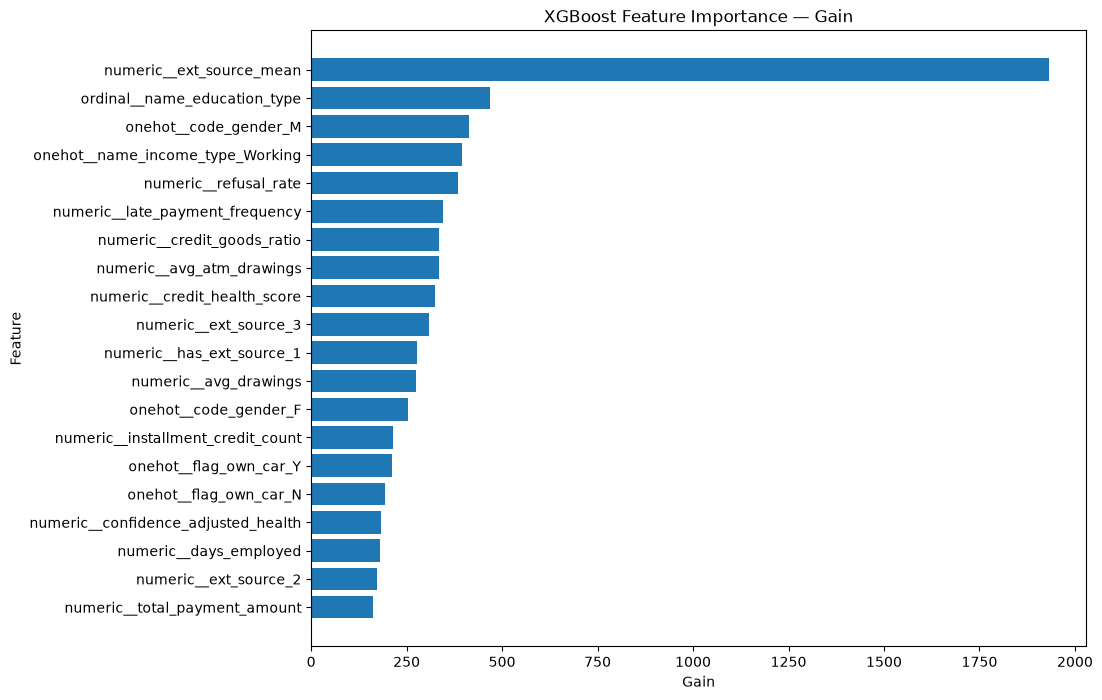

In [112]:
import matplotlib.pyplot as plt

top20 = importance_df.head(20).sort_values('importance')

plt.figure(figsize=(10, 8))

plt.barh(
    top20['feature_name'],
    top20['importance']
)

plt.xlabel('Gain')
plt.ylabel('Feature')
plt.title('XGBoost Feature Importance — Gain')

plt.show()

In [113]:
deployment_sample = x_test.sample(n=300, random_state=42)
deployment_sample.to_csv('deployment_sample.csv', index=False)

# Bu sadəcə İSTİFADƏ (inference) üçündür, TƏLİM üçün deyil

In [114]:
import joblib
print(joblib.__version__)

1.5.3


In [115]:
import joblib

# best_xgb - sizin yekun, ən yaxşı XGBoost pipeline-ınız
joblib.dump(best_xgb, 'final_model.pkl')

print('Model saxlanıldı!')

Model saxlanıldı!


In [116]:
import os
print(os.path.exists('final_model.pkl'))
print(os.path.getsize('final_model.pkl'), 'bytes')

True
633470 bytes


In [117]:
import shap

xgb_model = best_xgb.named_steps["model"]

explainer = shap.TreeExplainer(xgb_model)

X_transformed = best_xgb.named_steps["preprocess"].transform(x_dev)

shap_values = explainer.shap_values(X_transformed)

In [118]:
print(type(shap_values))
print(shap_values.shape)

<class 'numpy.ndarray'>
(260154, 242)


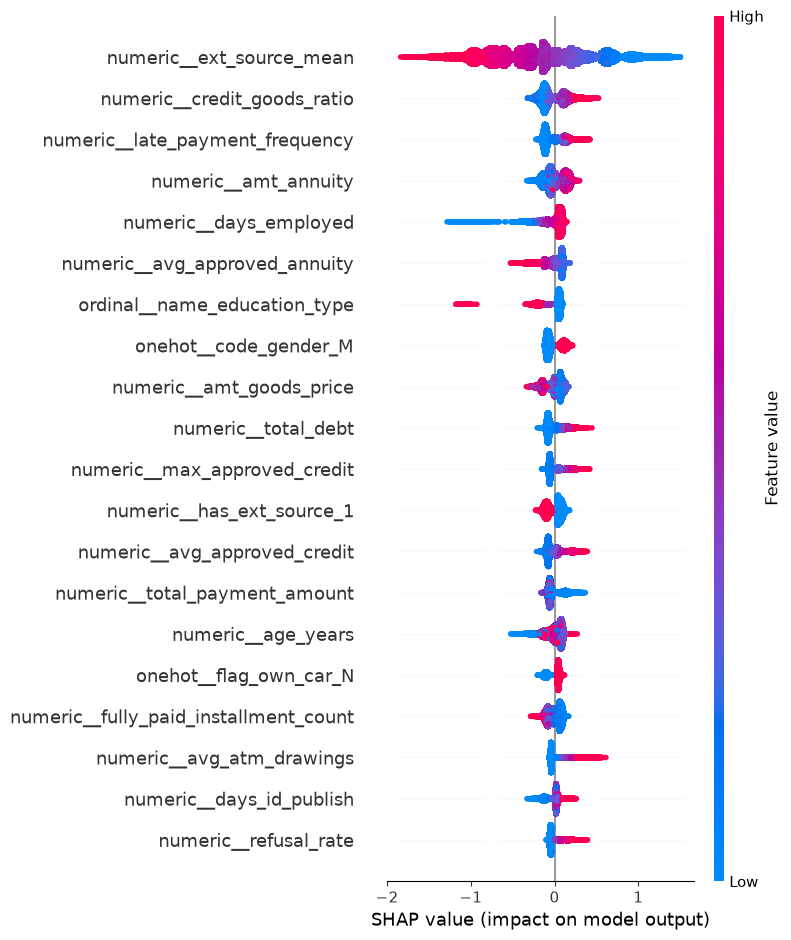

In [119]:
import shap
import matplotlib.pyplot as plt

# 1. XGBoost modelini götür
xgb_model = best_xgb.named_steps["model"]

# 2. SHAP explainer
explainer = shap.TreeExplainer(xgb_model)

# 3. Preprocessing
X_transformed = best_xgb.named_steps["preprocess"].transform(x_dev)

# 4. SHAP values
shap_values = explainer.shap_values(X_transformed)

# 5. Feature adlarını al
feature_names = best_xgb.named_steps["preprocess"].get_feature_names_out()

# 6. SHAP plot
shap.summary_plot(
    shap_values,
    X_transformed,
    feature_names=feature_names,
    show=False
)

plt.tight_layout()
plt.show()